# VoltRelay Energy: hackathon analysis notebook
Gradient Learnings Data Analytics Hackathon, 15 Nov 2025

The brief: swaps and revenue grew a lot in 2024-25, but failures, rider retention and margins got worse.
I want to figure out why, and what the next budget should go to.

Rough order of this notebook: load and look at the data, clean it, then go through Q1 to Q6 from the brief,
then a few deep dives (ticket text, anomalies, the budget question).

I used DuckDB for most of the heavy queries because swap_events has ~3.9M rows and pandas was slow on my laptop.

*AI use: I used Claude as a coding assistant for parts of the SQL/plotting code. Choices and conclusions are mine,
and everything below is produced by running this notebook.*

## 0. Setup
The data is downloaded automatically from the organizers' public Google Drive link (from the brief),
so this runs on Colab without uploading anything or connecting your Drive. The first run takes ~1-2 min for the download.

If the download fails (Google sometimes limits downloads of popular files), the cell asks you to pick
`HackathonData.zip` or the 8 CSVs from your computer instead. Locally it uses the `HackathonData/` folder if it's there.

In [1]:
import os, sys, glob, zipfile, json, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
DATA_URL = "https://drive.google.com/drive/folders/1qsjGWrgmEvOaf2Is2fh7RgVEkKd1V3df"   # organizers' public data folder
CSVS = ["swap_events","station_hourly_status","riders","batteries","support_tickets","stations","city_daily_context","fleet_partners"]

def find_data_dir():
    # look for a folder with all 8 CSVs; if only the zip is there, unzip it first
    roots = ["HackathonData", ".", "/content", "/content/drive/MyDrive"]
    for r in roots:
        for depth in ("", "*/", "*/*/"):
            for hit in glob.glob(os.path.join(r, depth + "swap_events.csv")):
                d = os.path.dirname(hit) + "/"
                if all(os.path.exists(d + t + ".csv") for t in CSVS): return d
    for r in roots:
        for depth in ("", "*/"):
            for z in glob.glob(os.path.join(r, depth + "*.zip")):
                with zipfile.ZipFile(z) as zf:
                    if any(n.endswith("swap_events.csv") for n in zf.namelist()):
                        print("unzipping", z)
                        zf.extractall("HackathonData")
                        return find_data_dir()
    return None

def download_data(dest="HackathonData/download/"):
    try:
        import gdown
    except ImportError:
        os.system(f'"{sys.executable}" -m pip -q install --disable-pip-version-check gdown'); import gdown
    print("downloading the data from the organizers' Google Drive folder (~850 MB)...")
    gdown.download_folder(DATA_URL, output=dest, quiet=True)   # files land in a subfolder named after the Drive folder
    d = find_data_dir()
    if not d or os.path.getsize(d + "swap_events.csv") < 500e6: raise IOError("download incomplete")
    return d

RAW_DIR = os.environ.get("RAW_DIR") or find_data_dir()
if not RAW_DIR:
    try:
        RAW_DIR = download_data()
    except Exception as e:
        print("download didn't work:", e)
if not RAW_DIR and IN_COLAB:
    print("Please pick HackathonData.zip (or all 8 CSV files) from your computer:")
    from google.colab import files
    files.upload()   # saves into the current folder
    RAW_DIR = find_data_dir()
assert RAW_DIR, "Couldn't get the data. Put HackathonData.zip (or the 8 CSVs) next to this notebook and re-run this cell."
print("data folder:", RAW_DIR)

# DuckDB runs the SQL. Colab's preinstalled version can be older and fails on some queries, so update it first
if IN_COLAB or "duckdb" not in sys.modules:
    try:
        import importlib.metadata as md; v = tuple(int(x) for x in md.version("duckdb").split(".")[:2])
    except Exception: v = (0, 0)
    if v < (1, 4): os.system(f'"{sys.executable}" -m pip -q install --disable-pip-version-check -U "duckdb>=1.4"')
import duckdb
print("duckdb", duckdb.__version__)
import pandas as pd, numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import pyarrow.csv as pacsv, pyarrow.parquet as pq
from IPython.display import display

OUT = "outputs/"; DATA = OUT + "data/"; FIG = OUT + "figures/"; TAB = OUT + "tables/"
for d in (DATA, FIG, TAB): os.makedirs(d, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# chart colours: orange = the thing I'm pointing at, blue/aqua for comparison, gray for background
BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#6250d6"
GRAY, LGRAY, INK, INK2 = "#a3a29b", "#d9d8d2", "#0b0b0b", "#52514e"
GEN_C = {"Gen1": ORANGE, "Gen2": BLUE, "Gen3": AQUA}
mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK2, "axes.edgecolor": "#c9c8c2", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "grid.linewidth": 0.7, "axes.axisbelow": True, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
    "lines.linewidth": 2.2, "figure.facecolor": "white"})
def save(fig, name, subtitle=None):
    if subtitle: fig.text(0.01, -0.01, subtitle, color=INK2, fontsize=8.5, ha="left", va="top", transform=fig.transFigure)
    fig.savefig(FIG + name + ".png"); plt.show()
KEY = {}   # headline numbers, saved at the end so the report/slides use the same values

con = duckdb.connect(); con.execute("SET preserve_insertion_order=false")
con.execute("SET memory_limit='4GB'"); con.execute("SET temp_directory='duckdb_tmp'")   # keeps RAM use safe on free Colab (spills to disk if needed)
try: con.execute("SET enable_progress_bar=false")   # the progress widget causes display errors in some notebooks
except Exception: pass
Q = lambda sql: con.execute(sql).df()

data folder: HackathonData/Hackathon Data Set _ Gradient/
duckdb 2.0.0


## 1. First look at the data
8 tables. `swap_events` is the main one, one row per swap attempt (including failed ones).

In [2]:
TABLES = ["swap_events","station_hourly_status","riders","batteries","support_tickets","stations","city_daily_context","fleet_partners"]
for t in TABLES:   # convert to parquet once, re-runs are much faster
    p = f"{DATA}raw_{t}.parquet"
    if not os.path.exists(p):
        # pyarrow straight to parquet uses much less memory than going through pandas (matters on Colab)
        pq.write_table(pacsv.read_csv(RAW_DIR + t + ".csv", convert_options=pacsv.ConvertOptions(strings_can_be_null=True)), p)
    con.execute(f"create or replace view raw_{t} as select * from '{p}'")
overview = pd.DataFrame([(t, *con.execute(f"select count(*), (select count(*) from (describe raw_{t})) from raw_{t}").fetchone()) for t in TABLES],
                        columns=["table","rows","columns"])
overview

,table,rows,columns
0,swap_events,3877013,22
1,station_hourly_status,1487712,14
2,riders,20000,12
3,batteries,6500,13
4,support_tickets,44000,12
5,stations,152,22
6,city_daily_context,3282,12
7,fleet_partners,12,12


In [3]:
Q("select * from raw_swap_events limit 5")

,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,soh_in_pct,soc_out_pct,soh_out_pct,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode
0,SW-003145729,RD-1016733,STN-HYD-085,2025-04-25 16:30:51,swap_completed,1,195,BAT-2W-102628,BAT-2W-102385,1.7,73.6,97.4,83.2,38.7,PARTNER,65.0,18.2,46.8,partner_invoice,1.811,v3.2.1,offline_batch
1,SW-003145730,RD-1016734,STN-JAI-150,2025-04-25 21:14:15,swap_completed,1,151,BAT-2W-106112,BAT-2W-100231,5.3,82.9,95.6,83.7,50.5,STD,65.0,0.0,65.0,partner_invoice,1.699,v3.2.1,realtime
2,SW-003145731,RD-1016735,STN-DEL-059,2025-04-25 21:51:49,swap_completed,1,209,BAT-2W-105299,BAT-2W-104356,1.0,70.4,98.8,70.9,50.5,PARTNER,65.0,18.2,46.8,partner_invoice,1.561,v3.2.1,realtime
3,SW-003145732,RD-1016736,STN-JAI-140,2025-04-25 20:52:14,swap_completed,1,177,BAT-2W-102574,BAT-2W-101723,13.7,71.0,95.1,71.1,-14.4,STD,65.0,0.0,65.0,partner_invoice,1.416,v3.2.0,realtime
4,SW-003145733,RD-1016739,STN-JAI-148,2025-04-25 21:53:17,swap_completed,1,116,BAT-2W-102008,BAT-2W-102940,4.0,82.8,98.1,84.0,55.0,PARTNER,65.0,6.5,58.5,partner_invoice,1.785,v3.2.0,realtime


In [4]:
# null counts in the main table
Q("summarize raw_swap_events")[["column_name","column_type","min","max","null_percentage"]]

,column_name,column_type,min,max,null_percentage
0,event_id,VARCHAR,SW-000000001,SW-003877013,0.00
1,rider_id,VARCHAR,RD-1000000,RD-1019998,0.00
2,station_id,VARCHAR,STN-BLR-001,STN-TST-02,0.00
3,event_ts,TIMESTAMP,2024-01-01 00:00:33,2025-06-30 23:59:23,0.00
4,event_type,VARCHAR,abandoned_queue,swap_completed,0.00
5,attempt_seq,BIGINT,1,1,0.00
6,queue_wait_sec,BIGINT,0,2400,0.00
7,battery_in_id,VARCHAR,BAT-2W-100000,BAT-3W-106494,0.73
8,battery_out_id,VARCHAR,BAT-2W-100000,BAT-3W-106494,5.96
9,soc_in_pct,DOUBLE,1.0,28.4,0.73


A few things already look odd: SOC/SOH go above 100, `km_since_last_swap` has negative values and some values
over 300 km. Will deal with these in cleaning.

In [5]:
Q("select event_type, count(*) n, round(100*count(*)/sum(count(*)) over (),2) pct, round(avg(queue_wait_sec)) avg_wait_s from raw_swap_events group by 1 order by n desc")

,event_type,n,pct,avg_wait_s
0,swap_completed,3645809,94.04,244.0
1,failed_no_charged_battery,134389,3.47,29.0
2,abandoned_queue,68533,1.77,703.0
3,cancelled_by_rider,16712,0.43,45.0
4,failed_system_error,11570,0.30,44.0


In [6]:
Q("select * from raw_fleet_partners")

,partner_id,partner_name,partner_segment,vehicle_class,contract_type,contract_start_date,discount_pct,amendment_date,discount_pct_after_amendment,peak_surcharge_billable,payment_terms_days,cities_active
0,FP-01,FeastFly,food_delivery,2W,volume_tiered,2023-04-01,10.0,NaT,NaN,Y,30,BLR|DEL|HYD|PUN|MUM|JAI
1,FP-02,ParcelNest,ecom_logistics,2W,pay_per_swap,2023-07-01,15.0,NaT,NaN,Y,30,BLR|DEL|HYD|MUM
2,FP-03,ZipDrop,quick_commerce,2W,volume_tiered,2023-06-01,12.0,2024-11-01,28.0,N,45,BLR|DEL|HYD|PUN|MUM|JAI
3,FP-04,CargoTuk,cargo_3w,3W,pay_per_swap,2023-09-01,8.0,NaT,NaN,Y,30,DEL|HYD|JAI
4,FP-05,Swiggle Go,food_delivery,2W,volume_tiered,2023-05-01,11.0,NaT,NaN,N,30,BLR|PUN|MUM
5,FP-06,RideMitra,bike_taxi,2W,pay_per_swap,2023-08-01,6.0,NaT,NaN,Y,15,BLR|DEL
6,FP-07,QuickCart,quick_commerce,2W,pay_per_swap,2024-01-15,9.0,NaT,NaN,Y,30,DEL|HYD
7,FP-08,DabbaXpress,food_delivery,2W,pay_per_swap,2024-02-01,8.0,NaT,NaN,Y,30,PUN|MUM
8,FP-09,HaulKing,cargo_3w,3W,pay_per_swap,2023-11-01,7.0,NaT,NaN,Y,45,JAI|DEL
9,FP-10,MetroMove,ecom_logistics,mixed,volume_tiered,2024-03-01,12.0,NaT,NaN,Y,30,BLR|MUM


Business events mentioned in the brief. I checked each one is actually visible in the data:
* base price went up on 1 Jul 2024 (2W ₹60 to ₹65, 3W ₹100 to ₹110), see query below
* peak/off-peak pilot in Bengaluru and Pune from 1 Oct 2024: peak +₹15, off-peak -₹8
* new battery supplier Kyron from mid-2024
* ZipDrop (biggest partner) discount went from 12% to 28% on 1 Nov 2024, and they don't pay the peak surcharge
* two expansion waves of 30 stations each (2024 H2, 2025 H1) on top of 90 launch stations

In [7]:
Q("""select date_trunc('month',s.event_ts) m, r.vehicle_class, min(list_price_inr) lo, max(list_price_inr) hi
     from raw_swap_events s join raw_riders r using(rider_id) where tariff_code='STD' and event_type='swap_completed'
     and date_trunc('month',s.event_ts) in ('2024-06-01','2024-07-01') group by all order by 2,1""")

,m,vehicle_class,lo,hi
0,2024-06-01,2W,60.0,60.0
1,2024-07-01,2W,65.0,65.0
2,2024-06-01,3W,100.0,100.0
3,2024-07-01,3W,110.0,110.0


## 2. Cleaning
Issues I found and what I did about them (counts get saved to `outputs/data/dq_log.csv`):

- **Test stations** (`STN-TST-*`): ~62k events that aren't real customers. Removed.
- **Firmware v3.2.0 clock bug**: between 10 Mar and 14 Apr 2025 the hourly pattern at these stations is shifted
  by exactly 5.5 hours, so it looks like UTC was logged as IST. Shifted them back (chart below).
- **km_since_last_swap** below 0 or above 200: looks like odometer resets. Set to null (~15.5k rows).
- **SOC/SOH above 100%**: sensor drift, capped at 100 (~9.8k rows).
- **Duplicates from offline sync**: the data dictionary mentions these, so I tried a few definitions
  (same rider + station + packs + event type within 180s etc.). Found none, but left the rule in.
- **home_city** has 21 spellings (BLR, Bombay, Gurgaon...). Mapped to the 6 cities.
- **Missing telemetry**: ~46k station-hours partial or missing. Kept as null, not zero.
- **CSAT** is mostly missing and not randomly: quick tickets get rated much more often. So I don't rely on it.
- **Ticket category** is unreliable, a lot of "other" tickets are actually range complaints. Re-tagged from the comment text (section 9).
- **payment_mode** is always `partner_invoice`, so I ignored it and used `plan_type`.

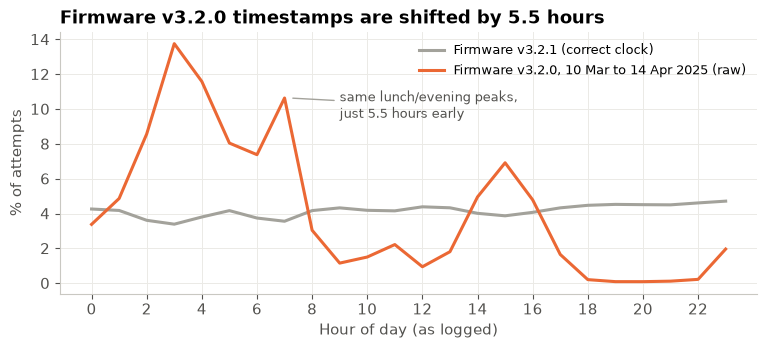

In [8]:
fw = Q("""select hour(event_ts) hr,
   avg((station_firmware='v3.2.0' and event_ts>='2025-03-10' and event_ts<'2025-04-15')::int) bug_window,
   avg((station_firmware='v3.2.1' and event_ts>='2025-03-10' and event_ts<'2025-04-15')::int) same_window_other_fw
   from raw_swap_events group by 1 order by 1""")
fw[["bug_window","same_window_other_fw"]] = fw[["bug_window","same_window_other_fw"]].div(fw[["bug_window","same_window_other_fw"]].sum())*100
fig, ax = plt.subplots(figsize=(9,3.4))
ax.plot(fw.hr, fw.same_window_other_fw, color=GRAY, label="Firmware v3.2.1 (correct clock)")
ax.plot(fw.hr, fw.bug_window, color=ORANGE, label="Firmware v3.2.0, 10 Mar to 14 Apr 2025 (raw)")
ax.annotate("same lunch/evening peaks,\njust 5.5 hours early", xy=(7.2,fw.bug_window[7]), xytext=(9,9.5), fontsize=9, color=INK2,
            arrowprops=dict(arrowstyle="-", color=GRAY))
ax.set_xticks(range(0,24,2)); ax.set_xlabel("Hour of day (as logged)"); ax.set_ylabel("% of attempts"); ax.legend(loc="upper right", fontsize=9)
ax.set_title("Firmware v3.2.0 timestamps are shifted by 5.5 hours")
save(fig, "dq_firmware_shift")

In [9]:
log = []
def L(table, check, value): log.append((table, check, value))
con.execute("create or replace table stations as select *, station_id like 'STN-TST%' is_test, monthly_rent_inr+monthly_maintenance_inr fixed_cost_month from raw_stations")

city_map = {"bengaluru":"Bengaluru","bangalore":"Bengaluru","blr":"Bengaluru","delhi ncr":"Delhi NCR","delhi":"Delhi NCR",
            "new delhi":"Delhi NCR","gurgaon":"Delhi NCR","gurugram":"Delhi NCR","noida":"Delhi NCR","mumbai":"Mumbai","bombay":"Mumbai",
            "mum":"Mumbai","hyderabad":"Hyderabad","hyd":"Hyderabad","pune":"Pune","pun":"Pune","jaipur":"Jaipur","jai":"Jaipur"}
r = Q("select * from raw_riders"); n_spell = r.home_city.nunique()
r["home_city"] = r.home_city.str.strip().str.lower().map(city_map)
assert r.home_city.notna().all()
r["partner_id"] = r.partner_id.fillna("INDEPENDENT"); r["signup_date"] = pd.to_datetime(r.signup_date)
con.register("r_df", r); con.execute("create or replace table riders as select * from r_df")
L("riders","home_city spellings -> cities", f"{n_spell} -> {r.home_city.nunique()}")

n_raw = con.execute("select count(*) from raw_swap_events").fetchone()[0]
con.execute("""create or replace table swaps as
with b as (select *, (station_firmware='v3.2.0' and event_ts >= TIMESTAMP '2025-03-09 18:30:00' and event_ts < TIMESTAMP '2025-04-14 18:30:00') ts_fixed from raw_swap_events)
select b.* exclude (event_ts, soc_in_pct, soh_in_pct, soc_out_pct, soh_out_pct, km_since_last_swap),
  case when ts_fixed then event_ts + interval 330 minute else event_ts end event_ts,
  least(soc_in_pct,100) soc_in_pct, least(soh_in_pct,100) soh_in_pct, least(soc_out_pct,100) soc_out_pct, least(soh_out_pct,100) soh_out_pct,
  (soc_out_pct>100 or soh_in_pct>100 or soh_out_pct>100) sensor_capped,
  case when km_since_last_swap<0 or km_since_last_swap>200 then null else km_since_last_swap end km_since_last_swap,
  (km_since_last_swap<0 or km_since_last_swap>200) km_outlier
from b""")
L("swaps","raw rows", n_raw)
L("swaps","timestamps shifted +5h30m (fw v3.2.0 bug)", con.execute("select sum(ts_fixed::int) from swaps").fetchone()[0])
L("swaps","km outliers -> NULL", con.execute("select sum(km_outlier::int) from swaps").fetchone()[0])
L("swaps","SOC/SOH >100 capped", con.execute("select sum(sensor_capped::int) from swaps").fetchone()[0])
con.execute("""create or replace table swaps as
with x as (select *, lag(event_ts) over (partition by rider_id, station_id, coalesce(battery_in_id,'-'), coalesce(battery_out_id,'-'), event_type order by event_ts) p from swaps)
select * exclude(p) from x where not (p is not null and date_diff('second', p, event_ts) <= 180)""")
n1 = con.execute("select count(*) from swaps").fetchone()[0]; L("swaps","near-duplicates removed", n_raw-n1)
con.execute("""create or replace table swaps as
select s.*, st.city, st.zone, st.location_type, st.host_type, st.charger_generation, st.expansion_wave, st.connectivity_tier, st.grid_tariff_inr_kwh,
  r.vehicle_class, r.partner_id, r.plan_type, r.signup_channel,
  cast(s.event_ts as date) event_date, hour(s.event_ts) hr, date_trunc('month', s.event_ts)::date as month,
  s.event_type='swap_completed' completed,
  s.event_type in ('failed_no_charged_battery','abandoned_queue','failed_system_error') service_failure
from swaps s join stations st using(station_id) join riders r using(rider_id) where not st.is_test""")
n2 = con.execute("select count(*) from swaps").fetchone()[0]; L("swaps","test-station rows removed", n1-n2); L("swaps","clean rows", n2)

con.execute("""create or replace table hourly as select h.*, st.city, st.charger_generation, st.expansion_wave, st.connectivity_tier,
  case when charged_2w_min is null then null else charged_2w_min=0 end stockout_2w
  from raw_station_hourly_status h join stations st using(station_id) where not st.is_test""")
L("hourly","station-hours with partial/missing telemetry kept NULL", con.execute("select count(*) from hourly where telemetry_status<>'ok'").fetchone()[0])
con.execute("""create or replace table batteries as select *, split_part(pack_type,'_',1) vclass,
  (supplier='Kyron' and manufacturing_lot in ('KY-2407','KY-2408','KY-2409')) kyron_bad from raw_batteries""")
con.execute("""create or replace table tickets as select t.*,
  case when regexp_matches(lower(rider_comment), 'charged batt|no batt|empty sta|sab batteries discharge') then 'No battery'
       when regexp_matches(lower(rider_comment), 'range|rnage|discharge fast|dying at|vehicle|bike problem|scooter weak') then 'Range / battery'
       when regexp_matches(lower(rider_comment), 'queue|line thi') then 'Queue'
       when regexp_matches(lower(rider_comment), 'surcharge') then 'Billing – surcharge'
       when regexp_matches(lower(rider_comment), 'amount') then 'Billing – amount'
       when regexp_matches(lower(rider_comment), 'app |qr code') then 'App'
       else 'Unclassified' end text_theme
  from raw_support_tickets t""")
con.execute("create or replace table ctx as select * from raw_city_daily_context")
con.execute("create or replace table partners as select * from raw_fleet_partners")
dq = pd.DataFrame(log, columns=["table","check","result"]); dq.to_csv(DATA+"dq_log.csv", index=False); dq

,table,check,result
0,riders,home_city spellings -> cities,21 -> 6
1,swaps,raw rows,3877013
2,swaps,timestamps shifted +5h30m (fw v3.2.0 bug),141280
3,swaps,km outliers -> NULL,15526
4,swaps,SOC/SOH >100 capped,9760
5,swaps,near-duplicates removed,0
6,swaps,test-station rows removed,62031
7,swaps,clean rows,3814982
8,hourly,station-hours with partial/missing telemetry k...,46131


## 3. Q1: How has the network performed over time?
To talk about margin I need a cost per swap. There's no cost column, so I built a simple one:

margin per swap = revenue - energy cost - battery wear

- energy cost = kWh to recharge x the station's grid tariff
- battery wear = pack cost spread over the pack's useful life. Useful life = how many swaps it takes to drop
  from its starting health to ~60% (retired packs in batteries.csv average 60.8%, so I used 60%).

The 60% is an assumption, so I'd trust the trend more than the exact rupee values.

In [10]:
con.execute("""create or replace table wear as
with b as (select battery_out_id bid, soh_out_pct, row_number() over (partition by battery_out_id order by event_ts) k from swaps where completed)
select bt.supplier, bt.vclass, bt.kyron_bad, -regr_slope(soh_out_pct, k) soh_loss_per_swap, avg(purchase_cost_inr) as cost, avg(initial_soh_pct) as init_soh, count(distinct bid) packs
from b join batteries bt on bt.battery_id=b.bid group by all""")
EOL = 60.0
wear = Q(f"select *, cost*soh_loss_per_swap/(init_soh-{EOL}) wear_inr, (init_soh-{EOL})/soh_loss_per_swap life_swaps from wear order by vclass, supplier")
wear

,supplier,vclass,kyron_bad,soh_loss_per_swap,cost,init_soh,packs,wear_inr,life_swaps
0,Amptek,2W,False,0.028860,31992.624310,99.192305,1098,23.558132,1358.028887
1,Cellora,2W,False,0.028825,31982.983944,99.181593,3035,23.529418,1359.276477
2,Kyron,2W,True,0.093610,31980.630119,99.197336,1385,76.375165,418.730750
3,Amptek,3W,False,0.032508,67824.431250,99.204525,209,56.239147,1206.000348
4,Cellora,3W,False,0.032294,67965.155174,99.197131,520,55.994757,1213.777130
5,Kyron,3W,True,0.076309,68209.372943,99.209312,76,132.749423,513.820484
6,Kyron,3W,False,0.032154,67772.940553,99.265641,177,55.498417,1221.168894


In [11]:
con.execute("""create or replace table cm as
select s.*, s.energy_to_recharge_kwh*s.grid_tariff_inr_kwh energy_cost, w.wear_inr wear_cost, bt.supplier, bt.kyron_bad
from swaps s join batteries bt on bt.battery_id=s.battery_out_id
join (select *, cost*soh_loss_per_swap/(init_soh-60) wear_inr from wear) w on w.supplier=bt.supplier and w.vclass=bt.vclass and w.kyron_bad=bt.kyron_bad
where s.completed""")
con.execute("""create or replace table cm as select cm.*, st.fixed_cost_month / n.n site_cost from cm
  join (select station_id, month, count(*) n from cm group by all) n using(station_id, month) join stations st using(station_id)""")
monthly = Q("""with a as (select month, count(*) attempts, sum(completed::int) completed, avg(service_failure::int)*100 fail_pct,
     sum(service_failure::int) failures, avg((event_type='failed_no_charged_battery')::int)*100 nobat_pct,
     avg((event_type='abandoned_queue')::int)*100 abandon_pct, count(distinct station_id) stations, count(distinct rider_id) riders from swaps group by 1),
  c as (select month, sum(amount_charged_inr)/1e6 revenue_m, avg(amount_charged_inr) rev_per_swap, avg(energy_cost) energy, avg(wear_cost) wear,
     avg(site_cost) site, avg(amount_charged_inr-energy_cost-wear_cost) cm_per_swap, avg(amount_charged_inr-energy_cost-wear_cost-site_cost) cm_full_per_swap,
     avg(km_since_last_swap) km_per_swap from cm group by 1)
  select * from a join c using(month) order by month""")
monthly.to_csv(TAB+"monthly_kpis.csv", index=False)
monthly.round(2)

,month,attempts,completed,fail_pct,failures,nobat_pct,abandon_pct,stations,riders,revenue_m,rev_per_swap,energy,wear,site,cm_per_swap,cm_full_per_swap,km_per_swap
0,2024-01-01,108278,103508.0,4.00,4327.0,2.44,1.27,90,4182,6.20,59.89,22.01,27.85,20.38,10.03,-10.34,73.68
1,2024-02-01,109271,104437.0,4.01,4377.0,2.40,1.30,90,4443,6.26,59.90,21.90,27.84,20.19,10.16,-10.03,73.26
2,2024-03-01,121487,116148.0,3.95,4795.0,2.37,1.27,90,4740,6.95,59.86,21.71,27.77,18.16,10.38,-7.78,72.70
3,2024-04-01,128991,120117.0,6.48,8365.0,4.13,2.05,90,5076,7.20,59.98,21.60,27.84,17.56,10.54,-7.02,71.48
4,2024-05-01,143189,125454.0,11.93,17081.0,7.82,3.81,90,5480,7.51,59.89,21.33,27.75,16.81,10.81,-6.00,68.49
5,2024-06-01,145880,130880.0,9.85,14374.0,6.43,3.12,90,5839,7.83,59.81,21.03,27.67,16.11,11.11,-5.01,69.16
6,2024-07-01,155343,148611.0,3.92,6096.0,2.35,1.28,90,6176,9.67,65.05,20.86,27.71,14.19,16.48,2.29,70.05
7,2024-08-01,168900,161688.0,3.83,6466.0,2.29,1.26,100,6711,10.51,65.00,20.65,27.69,14.67,16.66,2.00,69.39
8,2024-09-01,192479,184051.0,3.95,7610.0,2.39,1.25,108,7234,11.90,64.67,20.46,36.01,13.85,8.21,-5.64,65.03
9,2024-10-01,226458,216551.0,3.93,8910.0,2.38,1.26,120,7933,14.35,66.26,20.23,39.05,13.15,6.98,-6.17,62.80


In [12]:
h1 = lambda y: monthly[(monthly.month>=pd.Timestamp(f"{y}-01-01"))&(monthly.month<=pd.Timestamp(f"{y}-06-01"))]
a, b = h1(2024), h1(2025)
KEY.update(dict(
  attempts_total=int(monthly.attempts.sum()), completed_total=int(monthly.completed.sum()), revenue_total_m=round(monthly.revenue_m.sum(),1),
  completed_growth_pct=round((b.completed.sum()/a.completed.sum()-1)*100,1), revenue_growth_pct=round((b.revenue_m.sum()/a.revenue_m.sum()-1)*100,1),
  failures_growth_pct=round((b.failures.sum()/a.failures.sum()-1)*100,1), fail_rate_h1_24=round(a.failures.sum()/a.attempts.sum()*100,2),
  fail_rate_h1_25=round(b.failures.sum()/b.attempts.sum()*100,2),
  cm_jan24=round(monthly.cm_per_swap.iloc[0],2), cm_jul24=round(monthly.cm_per_swap.iloc[6],2), cm_nov24=round(monthly.cm_per_swap.iloc[10],2), cm_jun25=round(monthly.cm_per_swap.iloc[-1],2),
  cm_h1_24=round((a.cm_per_swap*a.completed).sum()/a.completed.sum(),2), cm_h1_25=round((b.cm_per_swap*b.completed).sum()/b.completed.sum(),2),
  km_jan24=round(monthly.km_per_swap.iloc[0],1), km_jun25=round(monthly.km_per_swap.iloc[-1],1),
  peak_fail_month=monthly.loc[monthly.fail_pct.idxmax(),"month"].strftime("%b %Y"), peak_fail_pct=round(monthly.fail_pct.max(),1)))
{k:KEY[k] for k in list(KEY)}

{'attempts_total': 3814982,
 'completed_total': 3586675,
 'revenue_total_m': np.float64(229.2),
 'completed_growth_pct': np.float64(142.9),
 'revenue_growth_pct': np.float64(162.7),
 'failures_growth_pct': np.float64(106.7),
 'fail_rate_h1_24': np.float64(7.04),
 'fail_rate_h1_25': np.float64(6.06),
 'cm_jan24': np.float64(10.03),
 'cm_jul24': np.float64(16.48),
 'cm_nov24': np.float64(5.64),
 'cm_jun25': np.float64(8.97),
 'cm_h1_24': np.float64(10.53),
 'cm_h1_25': np.float64(7.57),
 'km_jan24': np.float64(73.7),
 'km_jun25': np.float64(51.4),
 'peak_fail_month': 'May 2024',
 'peak_fail_pct': np.float64(11.9)}

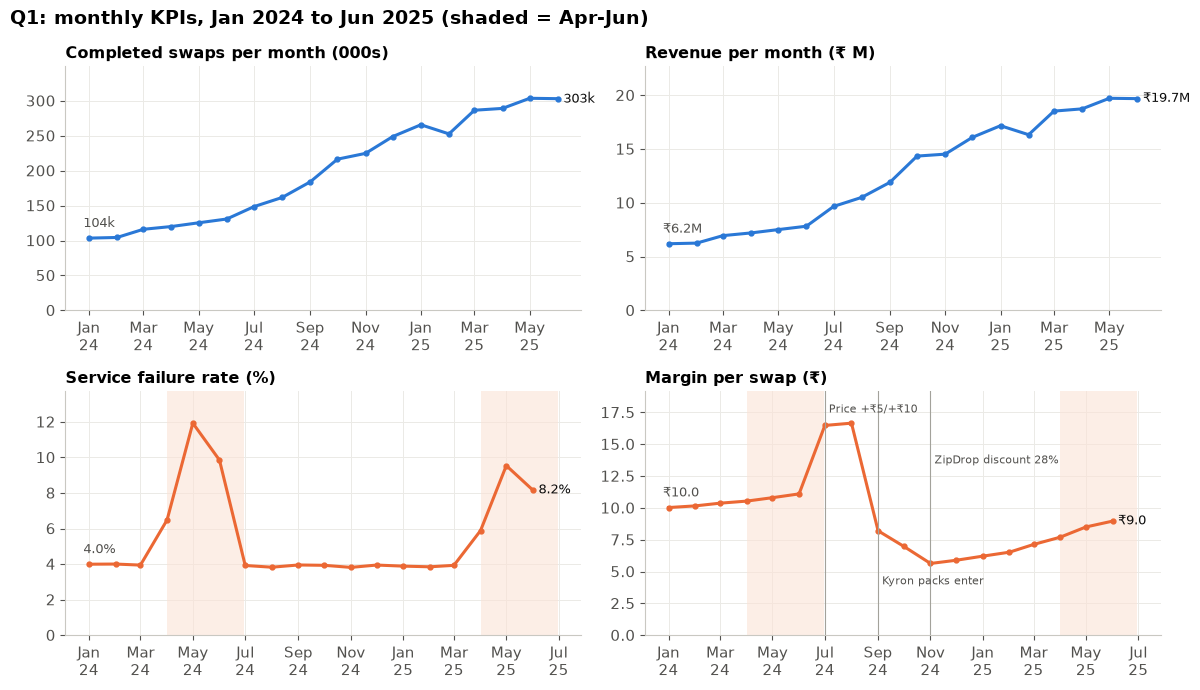

In [13]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
m = monthly.month
def panel(ax, y, color, title, fmt, ylim0=True):
    ax.plot(m, y, color=color, marker="o", ms=3.5); ax.set_title(title, fontsize=11.5)
    if ylim0: ax.set_ylim(0, y.max()*1.15)
    ax.annotate(fmt(y.iloc[-1]), (m.iloc[-1], y.iloc[-1]), xytext=(4,0), textcoords="offset points", va="center", fontsize=9, color=INK)
    ax.annotate(fmt(y.iloc[0]), (m.iloc[0], y.iloc[0]), xytext=(-4,8), textcoords="offset points", ha="left", fontsize=9, color=INK2)
    ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b\n%y"))
panel(axs[0,0], monthly.completed/1e3, BLUE, "Completed swaps per month (000s)", lambda v: f"{v:.0f}k")
panel(axs[0,1], monthly.revenue_m, BLUE, "Revenue per month (₹ M)", lambda v: f"₹{v:.1f}M")
panel(axs[1,0], monthly.fail_pct, ORANGE, "Service failure rate (%)", lambda v: f"{v:.1f}%")
panel(axs[1,1], monthly.cm_per_swap, ORANGE, "Margin per swap (₹)", lambda v: f"₹{v:.1f}")
for ax in axs[1]:
    for d in ["2024-04-01","2025-04-01"]: ax.axvspan(pd.Timestamp(d), pd.Timestamp(d)+pd.Timedelta(days=90), color="#fbe3d6", alpha=.6, lw=0)
ax = axs[1,1]
for d, t, yy in [("2024-07-01","Price +₹5/+₹10",17.5),("2024-09-01","Kyron packs enter",4.0),("2024-11-01","ZipDrop discount 28%",13.5)]:
    ax.axvline(pd.Timestamp(d), color=GRAY, lw=.8); ax.text(pd.Timestamp(d), yy, " "+t, fontsize=8, color=INK2)
fig.suptitle("Q1: monthly KPIs, Jan 2024 to Jun 2025 (shaded = Apr-Jun)", x=0.0, ha="left", fontsize=13.5, fontweight="bold"); fig.tight_layout()
save(fig, "q1_four_metrics")

These four don't move together. Swaps and revenue roughly tripled. Failure rate sits around 4% most of the year
but jumps to 10-12% in April-June, both years. Margin per swap went up after the July 2024 price rise and then
dropped from about September 2024, which is around when the Kyron packs and the bigger ZipDrop discount came in.

Note: the brief says failures grew faster than swaps. In absolute numbers and in summer, yes. But H1 vs H1 the
failure *count* grew ~107% while completed swaps grew ~143%, so the year-round rate didn't actually go up.

## 4. Q2: Where and when do failures happen?
My first guess was peak hours / congestion. Checking that against temperature and charger generation.

In [14]:
heat = Q("""select s.charger_generation gen, case when c.max_temp_c>=40 then '≥40°C' when c.max_temp_c>=35 then '35–40°C' when c.max_temp_c>=30 then '30–35°C' else '<30°C' end band,
   avg(service_failure::int)*100 fail, count(*) n from swaps s join ctx c on c.city=s.city and c.date=s.event_date group by all""")
order = ['<30°C','30–35°C','35–40°C','≥40°C']
hp = heat.pivot(index="band", columns="gen", values="fail").loc[order]
KEY.update(gen1_fail_40=round(hp.loc['≥40°C','Gen1'],1), gen3_fail_40=round(hp.loc['≥40°C','Gen3'],1), fail_cool=round(hp.loc['<30°C'].mean(),1))
seg = Q("""select vehicle_class, avg(service_failure::int)*100 fail from swaps group by 1""").set_index("vehicle_class").fail
KEY.update(fail_2w=round(seg['2W'],1), fail_3w=round(seg['3W'],1))
hp.round(1)

gen,Gen1,Gen2,Gen3
band,,,
<30°C,3.9,3.9,3.9
30–35°C,4.0,4.0,3.9
35–40°C,13.9,7.0,4.9
≥40°C,19.0,9.4,5.5


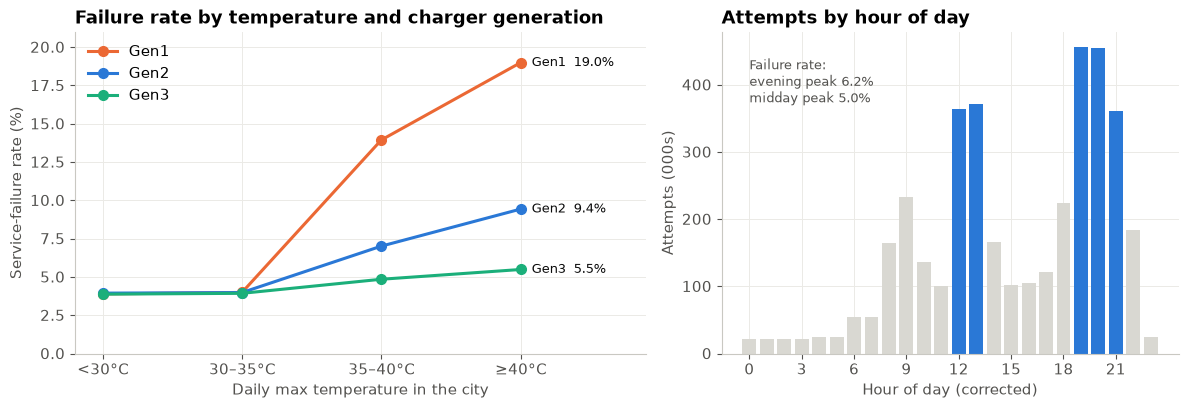

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios":[1.25,1]})
ax = axs[0]
for g in ["Gen1","Gen2","Gen3"]:
    ax.plot(order, hp[g], color=GEN_C[g], marker="o", ms=7, label=g)
    ax.annotate(f"{g}  {hp[g].iloc[-1]:.1f}%", (3, hp[g].iloc[-1]), xytext=(8,0), textcoords="offset points", va="center", fontsize=9.5, color=INK)
ax.set_ylabel("Service-failure rate (%)"); ax.set_xlabel("Daily max temperature in the city"); ax.set_ylim(0,21); ax.set_xlim(-0.2,3.9)
ax.legend(loc="upper left"); ax.set_title("Failure rate by temperature and charger generation")
hr = Q("select hr, avg(service_failure::int)*100 fail, count(*)/1e3 n from swaps group by 1 order by 1")
ax = axs[1]
ax.bar(hr.hr, hr.n, color=LGRAY, width=.8, label="Attempts (000s)")
ax.set_ylabel("Attempts (000s)"); ax.set_xlabel("Hour of day (corrected)"); ax.set_xticks(range(0,24,3))
ax.set_title("Attempts by hour of day")
for h in [12,13,19,20,21]: ax.bar(h, hr.n[h], color=BLUE, width=.8)
ax.text(0, hr.n.max()*0.82, f"Failure rate:\nevening peak {hr.fail[19:22].mean():.1f}%\nmidday peak {hr.fail[12:14].mean():.1f}%", fontsize=9, color=INK2)
fig.tight_layout(); save(fig, "q2_heat_generation_hours")

In [16]:
conc = Q("""with s as (select station_id, charger_generation gen, city, count(*) n, sum(service_failure::int) f from swaps group by all)
  select *, f/n*100 rate, sum(f) over (order by f desc)/sum(f) over ()*100 cum_share, row_number() over (order by f desc) rk from s order by f desc""")
top20 = conc.head(20)
KEY.update(top20_share=round(top20.cum_share.iloc[-1],1), top20_all_gen1=bool((top20.gen=="Gen1").all()),
           top20_cities=", ".join(sorted(top20.city.unique())), n_stations=len(conc),
           gen1_share_failures=round(conc[conc.gen=="Gen1"].f.sum()/conc.f.sum()*100,1), gen1_share_attempts=round(conc[conc.gen=="Gen1"].n.sum()/conc.n.sum()*100,1))
summer = Q("""select month(event_ts) in (4,5,6) summer, sum(service_failure::int) f from swaps group by 1""").set_index("summer").f
KEY["summer_share_failures"] = round(summer[True]/summer.sum()*100,1)
city = Q("select city, avg(service_failure::int)*100 fail, sum(service_failure::int) f, count(*) n from swaps group by 1 order by fail desc")
city["share_fail"] = city.f/city.f.sum()*100; city.to_csv(TAB+"city_failures.csv", index=False)
KEY["hot3_share_failures"] = round(city[city.city.isin(["Delhi NCR","Jaipur","Hyderabad"])].share_fail.sum(),1)
print({k:KEY[k] for k in ["top20_share","top20_all_gen1","top20_cities","gen1_share_failures","gen1_share_attempts","summer_share_failures","hot3_share_failures"]})
city.round(2)

{'top20_share': np.float64(31.0), 'top20_all_gen1': True, 'top20_cities': 'Delhi NCR, Hyderabad, Jaipur', 'gen1_share_failures': np.float64(58.5), 'gen1_share_attempts': np.float64(47.8), 'summer_share_failures': np.float64(55.4), 'hot3_share_failures': np.float64(63.3)}


,city,fail,f,n,share_fail
0,Jaipur,7.42,36195.0,487634,17.09
1,Delhi NCR,6.92,53227.0,768913,25.12
2,Hyderabad,6.26,44585.0,711930,21.05
3,Pune,4.56,25208.0,552910,11.90
4,Bengaluru,4.11,31366.0,763296,14.81
5,Mumbai,4.01,21268.0,530299,10.04


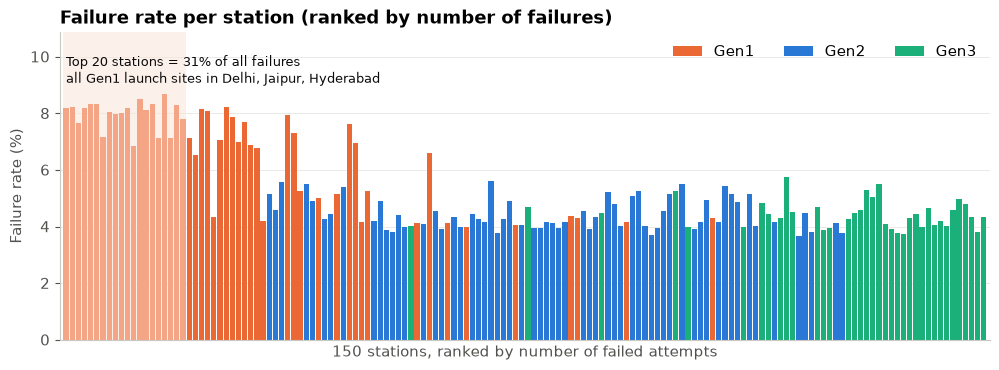

In [17]:
fig, ax = plt.subplots(figsize=(12, 4))
cols = [GEN_C[g] for g in conc.gen]
ax.bar(range(len(conc)), conc.rate, color=cols, width=.85)
for g in ["Gen1","Gen2","Gen3"]: ax.bar([0],[0], color=GEN_C[g], label=g)
ax.set_xlim(-1, len(conc)); ax.set_xticks([]); ax.set_xlabel(f"{len(conc)} stations, ranked by number of failed attempts"); ax.set_ylabel("Failure rate (%)")
ax.axvspan(-0.5, 19.5, color="#fbe3d6", alpha=.5, lw=0)
ax.text(0, conc.rate.max()+.4, f"Top 20 stations = {KEY['top20_share']:.0f}% of all failures\nall Gen1 launch sites in Delhi, Jaipur, Hyderabad", fontsize=9.5, color=INK)
ax.legend(loc="upper right", ncols=3); ax.set_ylim(0, conc.rate.max()+2.2)
ax.set_title("Failure rate per station (ranked by number of failures)")
save(fig, "q2_station_concentration")

This was the biggest surprise. Below 30°C all three charger generations fail about 4% of the time. On 40°C+ days
Gen1 goes to ~19% while Gen3 stays around 5.5%. So it's not really peak hours, it's heat at old chargers.

Other bits: 3W riders fail about twice as often as 2W. Queue wait for completed swaps is flat (~243s), so congestion
shows up as "no charged battery" and people leaving the queue, not as longer waits.

## 5. Q3: Stations and geography
Using the hourly station telemetry to see *why* Gen1 struggles in heat.

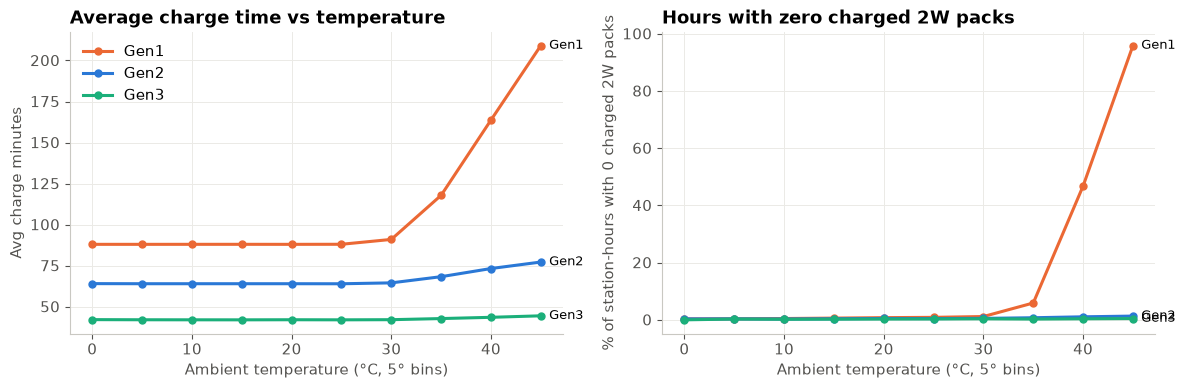

In [18]:
tel = Q("""select charger_generation gen, floor(ambient_temp_c/5)*5 t, avg(avg_charge_minutes) chg, avg(stockout_2w::int)*100 stockout, count(*) n
           from hourly where ambient_temp_c is not null group by all having count(*)>500 order by all""")
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for g in ["Gen1","Gen2","Gen3"]:
    d = tel[tel.gen==g]
    axs[0].plot(d.t, d.chg, color=GEN_C[g], marker="o", ms=5, label=g)
    axs[1].plot(d.t, d.stockout, color=GEN_C[g], marker="o", ms=5, label=g)
    axs[0].annotate(g, (d.t.iloc[-1], d.chg.iloc[-1]), xytext=(6,0), textcoords="offset points", va="center", fontsize=9)
    axs[1].annotate(g, (d.t.iloc[-1], d.stockout.iloc[-1]), xytext=(6,0), textcoords="offset points", va="center", fontsize=9)
axs[0].set_title("Average charge time vs temperature"); axs[0].set_ylabel("Avg charge minutes"); axs[0].set_xlabel("Ambient temperature (°C, 5° bins)")
axs[1].set_title("Hours with zero charged 2W packs"); axs[1].set_ylabel("% of station-hours with 0 charged 2W packs"); axs[1].set_xlabel("Ambient temperature (°C, 5° bins)")
axs[0].legend(loc="upper left"); fig.tight_layout(); save(fig, "q3_thermal_throttling")
g1 = tel[tel.gen=="Gen1"].set_index("t")
KEY.update(gen1_chg_cool=round(g1.chg.loc[20],0), gen1_chg_40=round(g1.chg.loc[40],0), gen1_chg_45=round(g1.chg.loc[45],0),
           gen1_stockout_40=round(g1.stockout.loc[40],0), gen1_stockout_45=round(g1.stockout.loc[45],0))

In [19]:
attr = pd.concat([Q(f"select '{c}' as attribute, {c} as value, avg(service_failure::int)*100 fail_pct, count(*) attempts, count(distinct station_id) stations from swaps group by all")
                  for c in ["charger_generation","location_type","expansion_wave","connectivity_tier","city"]])
tk = Q("""with t as (select station_id, count(*) tk, sum((text_theme='No battery')::int) nb from tickets where station_id is not null group by 1),
          s as (select station_id, count(*) n, avg(service_failure::int) f from swaps group by 1) select corr(tk/n, f) r from s join t using(station_id)""")
KEY["corr_tickets_failures"] = round(tk.r[0],2)
attr.round(2)

,attribute,value,fail_pct,attempts,stations
0,charger_generation,Gen3,4.40,372241,37
1,charger_generation,Gen1,6.80,1822034,51
2,charger_generation,Gen2,4.42,1620707,62
0,location_type,tech_park,4.77,147533,7
1,location_type,commercial_hub,5.75,1535743,44
2,location_type,highway_fuel_pump,4.69,329834,21
3,location_type,transit_hub,5.52,172667,10
4,location_type,residential,5.01,382274,21
5,location_type,market,5.80,1246931,47
0,expansion_wave,Wave1_2024H2,4.45,501098,30


Gen1 charge time roughly doubles once it's above 40°C, and the cabinets run out of charged packs most of those hours.
That explains the failures. Complaint rate per station also tracks failure rate (r about 0.63).
Location type and connectivity don't matter much in comparison. Poor connectivity explains the telemetry gaps, not failures
(system errors are ~0.3% everywhere).

### Did the expansion waves go where they were needed?

In [20]:
waves = Q("""select st.expansion_wave wave, count(distinct st.station_id) stations,
   sum((st.city in ('Delhi NCR','Jaipur','Hyderabad'))::int)/count(*) hot_share_dummy from stations st where not is_test group by 1 order by 1""")
wcity = Q("""select city, sum((expansion_wave<>'Launch')::int) new_stations from stations where not is_test group by 1""").merge(city[["city","share_fail"]])
wcity["share_new"] = wcity.new_stations/wcity.new_stations.sum()*100
util = Q("""select st.expansion_wave wave, st.charger_generation gen, count(distinct s.station_id) stations,
   count(*)/count(distinct s.station_id||cast(event_date as varchar)) swaps_per_station_day, avg(service_failure::int)*100 fail
   from swaps s join stations st using(station_id) where s.month>='2025-04-01' group by all order by all""")
wloc = Q("select expansion_wave, location_type, count(*) n from stations where not is_test group by all order by all")
g1y = Q("""select year(event_ts) y, avg(service_failure::int)*100 fail from swaps where month(event_ts) in (4,5,6) and charger_generation='Gen1'
           and city in ('Delhi NCR','Jaipur','Hyderabad') group by 1 order by 1""").set_index("y").fail
KEY.update(gen1_hot_summer24=round(g1y[2024],1), gen1_hot_summer25=round(g1y[2025],1),
           hot3_share_new_stations=round(wcity[wcity.city.isin(["Delhi NCR","Jaipur","Hyderabad"])].share_new.sum(),1),
           wave1_util=round(util[util.wave=="Wave1_2024H2"].swaps_per_station_day.mean(),1), launch_gen1_util=round(util[(util.wave=="Launch")&(util.gen=="Gen1")].swaps_per_station_day.iloc[0],1),
           wave1_resid_hwy=int(wloc[(wloc.expansion_wave=="Wave1_2024H2")&(wloc.location_type.isin(["residential","highway_fuel_pump"]))].n.sum()))
display(util.round(1)); display(wcity.round(1))

,wave,gen,stations,swaps_per_station_day,fail
0,Launch,Gen1,51,80.5,12.4
1,Launch,Gen2,39,69.5,5.2
2,Wave1_2024H2,Gen2,23,57.3,5.9
3,Wave1_2024H2,Gen3,7,63.7,4.7
4,Wave2_2025H1,Gen3,30,76.7,4.7


,city,new_stations,share_fail,share_new
0,Jaipur,8.0,17.1,13.3
1,Mumbai,9.0,10.0,15.0
2,Hyderabad,10.0,21.0,16.7
3,Bengaluru,12.0,14.8,20.0
4,Delhi NCR,12.0,25.1,20.0
5,Pune,9.0,11.9,15.0


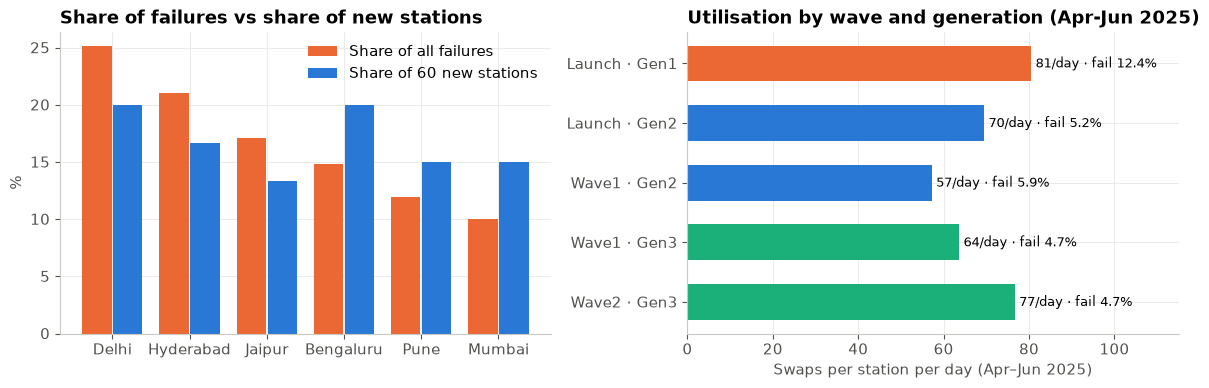

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
w = wcity.sort_values("share_fail", ascending=False); x = np.arange(len(w))
axs[0].bar(x-.2, w.share_fail, .38, color=ORANGE, label="Share of all failures")
axs[0].bar(x+.2, w.share_new, .38, color=BLUE, label="Share of 60 new stations")
axs[0].set_xticks(x, w.city.str.replace(" NCR","")); axs[0].set_ylabel("%"); axs[0].legend(loc="upper right")
axs[0].set_title("Share of failures vs share of new stations")
u = util.copy(); u["label"] = u.wave.str.replace("_2024H2","").str.replace("_2025H1","") + " · " + u.gen
axs[1].barh(u.label, u.swaps_per_station_day, color=[GEN_C[g] for g in u.gen], height=.6)
for i, (v, f) in enumerate(zip(u.swaps_per_station_day, u.fail)): axs[1].text(v+1, i, f"{v:.0f}/day · fail {f:.1f}%", va="center", fontsize=9)
axs[1].set_xlim(0, 115); axs[1].invert_yaxis(); axs[1].set_xlabel("Swaps per station per day (Apr–Jun 2025)")
axs[1].set_title("Utilisation by wave and generation (Apr-Jun 2025)")
fig.tight_layout(); save(fig, "q3_expansion_waves")

Not really. Delhi, Jaipur and Hyderabad have ~63% of failures but got about half of the 60 new stations.
Most Wave 1 sites are residential or highway pumps and they're the least used. And Gen1 sites in those three cities
failed ~15% in summer 2025, same as summer 2024. So the new stations didn't help where the problem was.

## 6. Q4: Batteries and equipment
I tried tracking individual packs first, but a lot of swaps happen *before* the pack's commission date (17-45% depending
on supplier), so the battery IDs aren't fully reliable. Comparing at supplier + lot level instead.

In [22]:
soh = Q("""select s.month, case when bt.kyron_bad then 'Kyron lots KY-2407/08/09' else bt.supplier end cohort, avg(soh_out_pct) soh
  from swaps s join batteries bt on bt.battery_id=s.battery_out_id where completed and bt.vclass='2W' group by all order by all""")
km = Q("""select floor(soh_in_pct/5)*5 soh_band, avg(km_since_last_swap) km, count(*) n from swaps where completed and vehicle_class='2W' and soh_in_pct>=55 group by 1 order by 1""")
w2 = wear.set_index(["supplier","vclass","kyron_bad"])
KEY.update(kyron_loss_ratio=round(w2.loc[("Kyron","2W",True),"soh_loss_per_swap"]/w2.loc[("Cellora","2W",False),"soh_loss_per_swap"],1),
           kyron_life=int(w2.loc[("Kyron","2W",True),"life_swaps"]), cellora_life=int(w2.loc[("Cellora","2W",False),"life_swaps"]),
           kyron_wear=round(w2.loc[("Kyron","2W",True),"wear_inr"],1), cellora_wear=round(w2.loc[("Cellora","2W",False),"wear_inr"],1),
           kyron_packs=int(Q("select count(*) from batteries where kyron_bad and vclass='2W'").iloc[0,0]),
           kyron_capex_m=round(Q("select sum(purchase_cost_inr)/1e6 from batteries where kyron_bad").iloc[0,0],1),
           kyron_share_2w=round(Q("select avg(bt.kyron_bad::int)*100 from swaps s join batteries bt on bt.battery_id=s.battery_out_id where completed and bt.vclass='2W' and s.month>='2024-10-01'").iloc[0,0],1),
           km_per_soh_pt=round(np.polyfit(km.soh_band, km.km, 1, w=km.n)[0],2))
kyr = Q("""select case when bt.kyron_bad then 'Kyron bad lots' else 'Other' end c, avg(km_since_last_swap) km, avg(soh_out_pct) soh from swaps s join batteries bt on bt.battery_id=s.battery_in_id
           where completed and bt.vclass='2W' and month='2025-06-01' group by 1""").set_index("c")
KEY.update(kyron_km_jun25=round(kyr.km["Kyron bad lots"],1), other_km_jun25=round(kyr.km["Other"],1))
lot3w = Q("select bt.manufacturing_lot lot, -regr_slope(soh_out_pct, k)*100 loss_per_100 from (select battery_out_id, soh_out_pct, row_number() over (partition by battery_out_id order by event_ts) k from swaps where completed) x join batteries bt on bt.battery_id=x.battery_out_id where bt.supplier='Kyron' group by 1 order by 1")
display(wear.round(3)); lot3w.round(2)

,supplier,vclass,kyron_bad,soh_loss_per_swap,cost,init_soh,packs,wear_inr,life_swaps
0,Amptek,2W,False,0.029,31992.624,99.192,1098,23.558,1358.029
1,Cellora,2W,False,0.029,31982.984,99.182,3035,23.529,1359.276
2,Kyron,2W,True,0.094,31980.630,99.197,1385,76.375,418.731
3,Amptek,3W,False,0.033,67824.431,99.205,209,56.239,1206.000
4,Cellora,3W,False,0.032,67965.155,99.197,520,55.995,1213.777
5,Kyron,3W,True,0.076,68209.373,99.209,76,132.749,513.820
6,Kyron,3W,False,0.032,67772.941,99.266,177,55.498,1221.169


,lot,loss_per_100
0,KY-2407,9.29
1,KY-2408,9.31
2,KY-2409,9.28
3,KY-2410,3.42
4,KY-2411,3.24
5,KY-2412,3.20
6,KY-2413,3.17
7,KY-2414,3.22
8,KY-2415,3.21
9,KY-2416,3.15


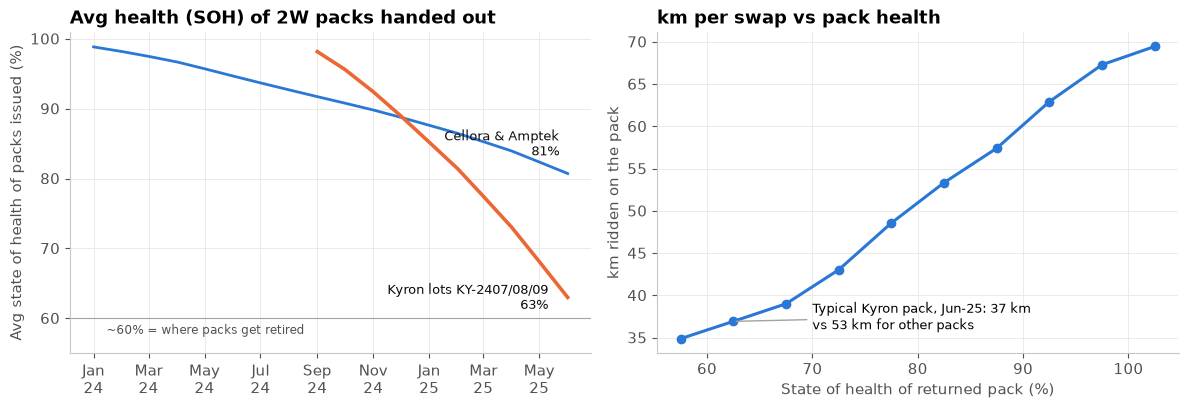

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
soh["cohort"] = soh.cohort.replace({"Cellora":"Cellora & Amptek", "Amptek":"Cellora & Amptek"}); soh = soh.groupby(["month","cohort"], as_index=False).soh.mean()
cc = {"Cellora & Amptek": BLUE, "Kyron lots KY-2407/08/09": ORANGE}
for c, d in soh.groupby("cohort"):
    axs[0].plot(d.month, d.soh, color=cc[c], lw=2.6 if "Kyron" in c else 2)
    axs[0].annotate(f"{c}\n{d.soh.iloc[-1]:.0f}%", (d.month.iloc[-1], d.soh.iloc[-1]), xytext=(-6, 10) if "Kyron" not in c else (-14, 0), textcoords="offset points", fontsize=9, ha="right", va="bottom" if "Kyron" not in c else "center", color=INK)
axs[0].axhline(60, color=GRAY, lw=.8); axs[0].text(pd.Timestamp("2024-01-15"), 59.2, "~60% = where packs get retired", fontsize=8.5, color=INK2, va="top")
axs[0].set_ylabel("Avg state of health of packs issued (%)"); axs[0].set_ylim(55, 101)
axs[0].set_title("Avg health (SOH) of 2W packs handed out")
axs[0].xaxis.set_major_formatter(mpl.dates.DateFormatter("%b\n%y"))
axs[1].plot(km.soh_band+2.5, km.km, color=BLUE, marker="o", ms=6)
axs[1].set_xlabel("State of health of returned pack (%)"); axs[1].set_ylabel("km ridden on the pack")
axs[1].set_title("km per swap vs pack health")
axs[1].annotate(f"Typical Kyron pack, Jun-25: {KEY['kyron_km_jun25']:.0f} km\nvs {KEY['other_km_jun25']:.0f} km for other packs", (62.5, km.set_index("soh_band").km.get(60, 37)), xytext=(70,36), fontsize=9, arrowprops=dict(arrowstyle="-", color=GRAY))
fig.tight_layout(); save(fig, "q4_battery_kyron")

Cellora and Amptek look basically the same (~2.9 health points lost per 100 swaps). Kyron lots KY-2407, 2408 and 2409
are much worse: about 3.2x faster, so they hit 60% after ~420 swaps instead of ~1,360. That's 1,385 packs and about a
quarter of 2W swaps from Oct 2024.

Riders would feel this as range: by June 2025 these packs gave ~37 km per swap vs ~53 km for others.
All of them were retired on 15 Jun 2025. Kyron's later 3W lots look normal, so it seems to be a bad batch, not the supplier overall.
(Weird: some of the retired packs still show up in swaps after 15 Jun.)

## 7. Q5: Pricing and partners
Breaking down the change in margin per swap between H1 2024 and H1 2025.

In [24]:
bridge = {}
for y in (2024, 2025):
    d = Q(f"""select avg(amount_charged_inr) rev, avg(energy_cost) energy, avg(wear_cost) wear, avg(case when kyron_bad then wear_cost end) kw,
             avg(kyron_bad::int) kshare, avg(site_cost) site from cm where month between '{y}-01-01' and '{y}-06-01'""").iloc[0]
    bridge[y] = d
b24, b25 = bridge[2024], bridge[2025]
# split revenue change into: list price, ZipDrop's extra 16% discount, peak pilot, and whatever's left
rev_parts = Q("""select
   avg(case when month between '2025-01-01' and '2025-06-01' then list_price_inr end) - avg(case when month between '2024-01-01' and '2024-06-01' then list_price_inr end) list_change,
   -avg(case when month between '2025-01-01' and '2025-06-01' and partner_id='FP-03' then list_price_inr*0.16 else 0 end) filter (where month between '2025-01-01' and '2025-06-01') zipdrop,
   avg(case when month between '2025-01-01' and '2025-06-01' then amount_charged_inr-(list_price_inr-discount_inr) end) peak_net
   from cm""").iloc[0]
steps = [("CM H1-2024", b24.rev-b24.energy-b24.wear, "total"),
         ("Base price rise", rev_parts.list_change, "d"), ("Peak pilot (net)", rev_parts.peak_net, "d"), ("ZipDrop 28% discount", rev_parts.zipdrop, "d"),
         ("Other revenue mix", (b25.rev-b24.rev)-rev_parts.list_change-rev_parts.peak_net-rev_parts.zipdrop, "d"),
         ("Energy (lower)", -(b25.energy-b24.energy), "d"),
         ("Kyron extra wear", -(b25.wear-b24.wear), "d"), ("CM H1-2025", b25.rev-b25.energy-b25.wear, "total")]
br = pd.DataFrame(steps, columns=["step","value","kind"]); br.to_csv(TAB+"cm_bridge.csv", index=False)
KEY.update({"bridge_"+s.split()[0].lower(): round(v,2) for s,v,_ in steps[1:-1]})
KEY.update(zipdrop_bridge=round(rev_parts.zipdrop,2), kyron_bridge=round(-(b25.wear-b24.wear),2), price_bridge=round(rev_parts.list_change,2))
br.round(2)

,step,value,kind
0,CM H1-2024,10.53,total
1,Base price rise,5.17,d
2,Peak pilot (net),1.71,d
3,ZipDrop 28% discount,-1.67,d
4,Other revenue mix,-0.33,d
5,Energy (lower),3.43,d
6,Kyron extra wear,-11.28,d
7,CM H1-2025,7.57,total


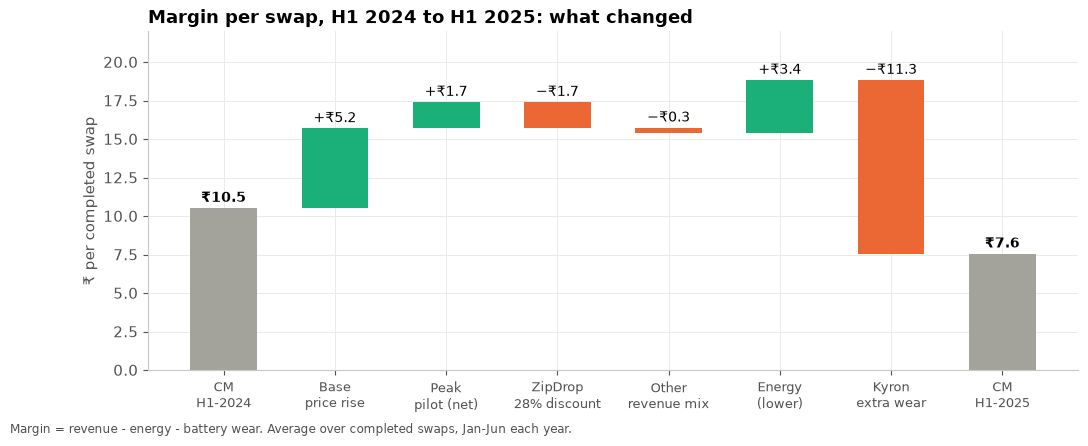

In [25]:
fig, ax = plt.subplots(figsize=(12, 4.4))
cum = 0
for i, (s, v, k) in enumerate(steps):
    if k == "total":
        ax.bar(i, v, color=GRAY, width=.6); cum = v; ax.text(i, v+.4, f"₹{v:.1f}", ha="center", fontsize=10, fontweight="bold")
    else:
        ax.bar(i, v, bottom=cum, color=AQUA if v>0 else ORANGE, width=.6)
        ax.text(i, max(cum, cum+v)+.4, f"{'+' if v>0 else '−'}₹{abs(v):.1f}", ha="center", fontsize=10); cum += v
ax.set_xticks(range(len(steps)), [s.replace(" ", "\n", 1) for s,_,_ in steps], fontsize=9.5); ax.set_ylabel("₹ per completed swap"); ax.set_ylim(0, 22)
ax.set_title("Margin per swap, H1 2024 to H1 2025: what changed")
save(fig, "q5_margin_bridge", "Margin = revenue - energy - battery wear. Average over completed swaps, Jan-Jun each year.")

In [26]:
pcm = Q("""select coalesce(p.partner_name, 'Independent riders') partner, cm.partner_id, count(*) swaps, sum(amount_charged_inr)/1e6 revenue_m, avg(amount_charged_inr) rev_per_swap,
   avg(amount_charged_inr-energy_cost-wear_cost) cm_per_swap, sum(amount_charged_inr-energy_cost-wear_cost)/1e6 cm_total_m,
   avg(amount_charged_inr-energy_cost-wear_cost-site_cost) cm_full_per_swap, avg((hr in (12,13,19,20,21))::int)*100 peak_hour_share, any_value(p.peak_surcharge_billable) surcharge, any_value(p.payment_terms_days) terms
   from cm left join partners p using(partner_id) where month between '2025-01-01' and '2025-06-01' group by all order by swaps desc""")
pcm.to_csv(TAB+"partner_economics_2025H1.csv", index=False)
z = pcm.set_index("partner_id")
KEY.update(zip_rev_per_swap=round(z.loc["FP-03","rev_per_swap"],1), zip_cm=round(z.loc["FP-03","cm_per_swap"],1),
           other_partner_cm=round(pcm[~pcm.partner_id.isin(["FP-03","INDEPENDENT","FP-04","FP-09"])].eval("cm_per_swap*swaps").sum()/pcm[~pcm.partner_id.isin(["FP-03","INDEPENDENT","FP-04","FP-09"])].swaps.sum(),1),
           zip_swap_share=round(z.loc["FP-03","swaps"]/pcm.swaps.sum()*100,1), zip_peak_share=round(z.loc["FP-03","peak_hour_share"],1),
           indep_cm=round(z.loc["INDEPENDENT","cm_per_swap"],1))
zs = Q("""select month>='2024-11-01' as post, avg((partner_id='FP-03')::int)*100 as share from swaps where completed and month between '2024-05-01' and '2025-04-01' group by 1""").set_index("post").share
KEY.update(zip_share_pre=round(zs[False],1), zip_share_post=round(zs[True],1))
pcm.round(2)

,partner,partner_id,swaps,revenue_m,rev_per_swap,cm_per_swap,cm_total_m,cm_full_per_swap,peak_hour_share,surcharge,terms
0,Independent riders,INDEPENDENT,581013,40.73,70.10,15.31,8.89,3.53,58.72,None,<NA>
1,ZipDrop,FP-03,262396,12.76,48.64,-6.76,-1.77,-17.89,63.42,N,45
2,FeastFly,FP-01,245889,15.73,63.98,9.39,2.31,-2.25,65.34,Y,30
3,ParcelNest,FP-02,137592,7.92,57.53,2.56,0.35,-9.22,19.55,Y,30
4,Swiggle Go,FP-05,111004,6.69,60.31,5.49,0.61,-6.30,66.17,N,30
5,CargoTuk,FP-04,62042,6.29,101.38,0.56,0.03,-11.32,17.34,Y,30
6,QuickCart,FP-07,58755,3.78,64.26,10.03,0.59,-1.67,62.85,Y,30
7,RideMitra,FP-06,58741,3.76,64.09,9.62,0.56,-2.84,25.45,Y,15
8,DabbaXpress,FP-08,44433,2.91,65.46,10.97,0.49,-0.67,65.25,Y,30
9,MetroMove,FP-10,40313,2.40,59.59,4.31,0.17,-7.52,19.56,Y,30


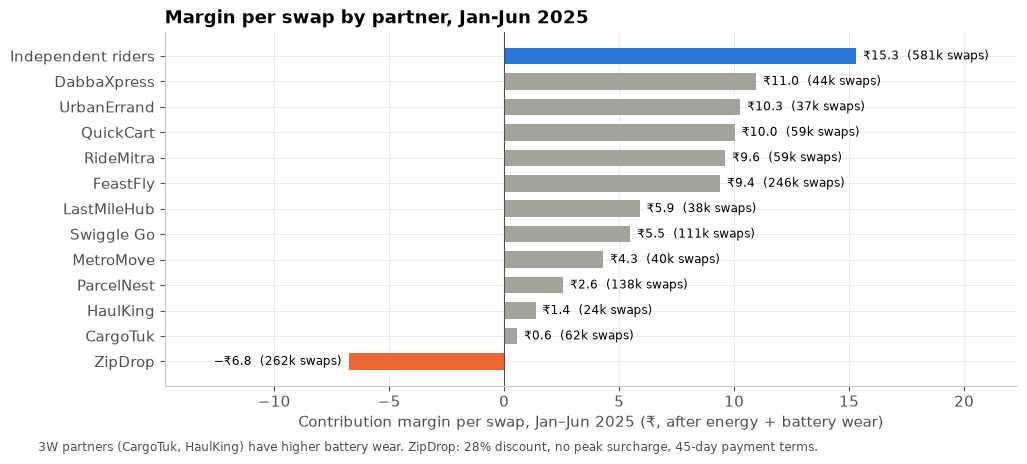

In [27]:
fig, ax = plt.subplots(figsize=(11, 4.6))
p = pcm.sort_values("cm_per_swap")
colors = [ORANGE if pid=="FP-03" else (BLUE if pid=="INDEPENDENT" else GRAY) for pid in p.partner_id]
ax.barh(p.partner, p.cm_per_swap, color=colors, height=.65)
for i, (v, s) in enumerate(zip(p.cm_per_swap, p.swaps)): ax.text(v + (0.3 if v>=0 else -0.3), i, f"{'−' if v<0 else ''}₹{abs(v):.1f}  ({s/1e3:.0f}k swaps)", va="center", ha="left" if v>=0 else "right", fontsize=8.5)
ax.axvline(0, color=INK2, lw=.8); ax.set_xlabel("Contribution margin per swap, Jan–Jun 2025 (₹, after energy + battery wear)")
ax.set_xlim(p.cm_per_swap.min()-8, p.cm_per_swap.max()+7)
ax.set_title("Margin per swap by partner, Jan-Jun 2025")
save(fig, "q5_partner_cm", "3W partners (CargoTuk, HaulKing) have higher battery wear. ZipDrop: 28% discount, no peak surcharge, 45-day payment terms.")

ZipDrop is our biggest partner but makes the least per swap (negative after battery wear), and the bigger discount
didn't bring more volume: their share was ~15% before and after.

### Did the peak pricing pilot actually move demand?
Comparing Bengaluru + Pune (pilot from Oct 2024) against the other 4 cities, before vs after: a simple
difference-in-differences on the share of swaps in peak hours (12-13h, 19-21h).

In [28]:
did_m = Q("""select month, plan_type<>'partner_billed' payg, city in ('Bengaluru','Pune') pilot, avg((hr in (12,13,19,20,21))::int)*100 peak_share, count(*) n
             from swaps where completed group by all order by all""")
did_m["post"] = (did_m.month >= pd.Timestamp("2024-10-01")).astype(int); did_m["pilot"] = did_m.pilot.astype(int)
res = {}
for seg, d in did_m.groupby("payg"):
    mdl = smf.wls("peak_share ~ pilot + pilot:post + C(month)", data=d, weights=d.n).fit(cov_type="HC1")
    res["Independent (PAYG/prepaid)" if seg else "Partner-billed"] = (mdl.params["pilot:post"], *mdl.conf_int().loc["pilot:post"])
did = pd.DataFrame(res, index=["DiD (pp)","lo95","hi95"]).T.round(2); display(did)
arps = Q("""select city in ('Bengaluru','Pune') pilot, month>='2024-10-01' post, avg(amount_charged_inr) arps from swaps where completed and plan_type<>'partner_billed' and month>='2024-07-01' group by all""")
arps = arps.pivot(index="pilot", columns="post", values="arps")
KEY.update(did_indep=did.loc["Independent (PAYG/prepaid)","DiD (pp)"], did_partner=did.loc["Partner-billed","DiD (pp)"],
           pilot_arps_uplift=round((arps.loc[True,True]-arps.loc[True,False])-(arps.loc[False,True]-arps.loc[False,False]),2))
spr = Q("""select plan_type, month, count(*)/count(distinct rider_id) spr from swaps where completed and month between '2024-04-01' and '2024-09-01' group by all""")
spr_p = spr.assign(post=spr.month>=pd.Timestamp("2024-07-01")).groupby(["plan_type","post"]).spr.mean().unstack()
KEY["payg_spr_change_pct"] = round((spr_p.loc["pay_as_you_go",True]/spr_p.loc["pay_as_you_go",False]-1)*100,1)
display(spr_p.round(1)); print("ARPS uplift DiD (₹):", KEY["pilot_arps_uplift"])

,DiD (pp),lo95,hi95
Partner-billed,-3.26,-3.72,-2.80
Independent (PAYG/prepaid),-2.51,-3.00,-2.02


post,False,True
plan_type,,
partner_billed,24.8,26.4
pay_as_you_go,20.1,21.6
prepaid_pack,20.4,21.9


ARPS uplift DiD (₹): 7.99


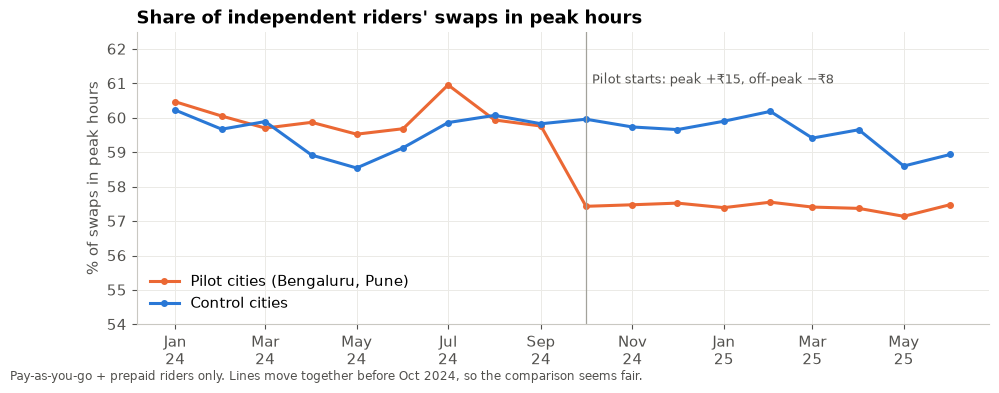

In [29]:
fig, ax = plt.subplots(figsize=(11, 3.8))
d = did_m[did_m.payg]
for pil, col, lab in [(1, ORANGE, "Pilot cities (Bengaluru, Pune)"), (0, BLUE, "Control cities")]:
    x = d[d.pilot==pil]; ax.plot(x.month, x.peak_share, color=col, marker="o", ms=4, label=lab)
ax.axvline(pd.Timestamp("2024-10-01"), color=GRAY, lw=.9); ax.text(pd.Timestamp("2024-10-05"), 61, "Pilot starts: peak +₹15, off-peak −₹8", fontsize=9, color=INK2)
ax.set_ylim(54, 62.5); ax.set_ylabel("% of swaps in peak hours"); ax.legend(loc="lower left")
ax.set_title("Share of independent riders' swaps in peak hours")
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b\n%y"))
save(fig, "q5_peak_pilot_did", "Pay-as-you-go + prepaid riders only. Lines move together before Oct 2024, so the comparison seems fair.")

Riders don't seem very price sensitive. After the July 2024 price rise, swaps per pay-as-you-go rider actually went up a bit.
The peak pilot only moved about 2.5 percentage points of swaps out of peak hours, but it did add ~₹8 per swap.
So it works for revenue, not really for congestion. Also ZipDrop and Swiggle Go are exempt from the surcharge,
and ZipDrop does most of its swaps in peak hours.

## 8. Q6: Why don't new riders come back?
Setup: for riders who signed up in 2024-25 (first swap before 2 Mar 2025), I look at what happened in their
first 30 days, then check whether they made any swap in days 61-120. No swap = didn't return.
I kept the two windows separate so the outcome can't leak into the inputs. Then a logistic regression.

In [30]:
con.execute("""create or replace table newr as
with a as (select rider_id, min(event_ts) f0 from swaps group by 1),
e as (select s.*, a.f0 from swaps s join a using(rider_id) where s.event_ts < a.f0 + interval 30 day),
later as (select a.rider_id, count(s.event_id) n_later from a left join swaps s on s.rider_id=a.rider_id and s.event_ts >= a.f0 + interval 60 day and s.event_ts < a.f0 + interval 120 day group by 1)
select a.rider_id, a.f0, count(*) att30, avg(service_failure::int) failrate, avg((event_type='abandoned_queue')::int) abrate,
  avg(km_since_last_swap) km, avg(bt.kyron_bad::int) filter (where completed) kyron_share, avg((tariff_code='PEAK')::int) filter (where completed) peak_share,
  any_value(h.station_id) home_station, any_value(h.city) city, any_value(l.n_later) n_later
from a join e using(rider_id) left join batteries bt on bt.battery_id=e.battery_out_id join later l using(rider_id)
join (select * from (select rider_id, station_id, city, row_number() over (partition by rider_id order by count(*) desc, station_id) rn
      from e group by rider_id, station_id, city) where rn=1) h using(rider_id) group by 1,2""")
nr = Q("""select n.*, r.plan_type, r.vehicle_class, r.signup_channel, r.partner_id, st.charger_generation home_gen,
   (st.competitor_within_1_5km_since is not null and st.competitor_within_1_5km_since <= n.f0 + interval 120 day)::int competitor,
   c.tmax30, c.promo120, coalesce(t.tk,0) tickets30
  from newr n join riders r using(rider_id) join stations st on st.station_id=n.home_station
  left join lateral (select avg(max_temp_c) tmax30, avg(competitor_promo_active::int) promo120 from ctx where ctx.city=n.city and ctx.date between cast(n.f0 as date) and cast(n.f0 as date)+30) c on true
  left join (select n2.rider_id, count(*) tk from tickets t join newr n2 using(rider_id) where t.created_ts < n2.f0 + interval 30 day group by 1) t using(rider_id)
  where r.signup_date >= '2024-01-01' and n.f0 < '2025-03-02'""")
nr["churn"] = (nr.n_later==0).astype(int)
nr = nr.assign(fail10=nr.failrate*10, km10=nr.km/10, hot=(nr.tmax30>=35).astype(int), log_att=np.log(nr.att30),
               peak=nr.peak_share.fillna(0), any_ticket=(nr.tickets30>0).astype(int)).dropna(subset=["km10","kyron_share"])
nr.to_parquet(DATA+"new_rider_features.parquet")
KEY.update(new_riders_n=len(nr), new_churn_rate=round(nr.churn.mean()*100,1))
f = "churn ~ fail10 + km10 + peak + hot + competitor + promo120 + any_ticket + C(plan_type) + C(vehicle_class) + C(home_gen) + C(signup_channel) + log_att"
mdl = smf.logit(f, data=nr).fit(disp=0)
orr = pd.DataFrame({"odds_ratio": np.exp(mdl.params), "lo95": np.exp(mdl.conf_int()[0]), "hi95": np.exp(mdl.conf_int()[1]), "p_value": mdl.pvalues}).drop("Intercept")
orr.to_csv(TAB+"new_rider_churn_model.csv"); print(f"n={len(nr)}, pseudo-R2={mdl.prsquared:.3f}"); orr.round(3)

n=11775, pseudo-R2=0.108


,odds_ratio,lo95,hi95,p_value
C(plan_type)[T.pay_as_you_go],0.551,0.413,0.734,0.000
C(plan_type)[T.prepaid_pack],0.520,0.381,0.709,0.000
C(vehicle_class)[T.3W],1.045,0.803,1.360,0.743
C(home_gen)[T.Gen2],0.992,0.889,1.107,0.884
C(home_gen)[T.Gen3],0.961,0.704,1.310,0.799
C(signup_channel)[T.field_agent],0.830,0.635,1.084,0.171
C(signup_channel)[T.partner_onboarding],0.902,0.662,1.230,0.514
C(signup_channel)[T.referral],1.184,0.976,1.435,0.086
fail10,1.388,1.267,1.521,0.000
km10,0.884,0.822,0.951,0.001


In [31]:
fb = nr[nr.att30>=20].groupby(pd.cut(nr.failrate*100, [-0.1,2,5,10,20,100], labels=["0–2%","2–5%","5–10%","10–20%",">20%"]), observed=True).churn.agg(["mean","size"])
fb["mean"] *= 100; display(fb.round(1))
heat_only = smf.logit("churn ~ hot + log_att + C(vehicle_class)", data=nr).fit(disp=0)
heat_ctrl = smf.logit("churn ~ hot + fail10 + log_att + C(vehicle_class)", data=nr).fit(disp=0)
KEY.update(or_fail=round(orr.loc["fail10","odds_ratio"],2), or_km=round(orr.loc["km10","odds_ratio"],2), or_peak=round(orr.loc["peak","odds_ratio"],2),
           or_peak_p=round(orr.loc["peak","p_value"],3), or_competitor=round(orr.loc["competitor","odds_ratio"],2), or_competitor_p=round(orr.loc["competitor","p_value"],2),
           or_hot_alone=round(np.exp(heat_only.params["hot"]),2), or_hot_ctrl=round(np.exp(heat_ctrl.params["hot"]),2),
           churn_lowfail=round(fb["mean"].iloc[0],1), churn_highfail=round(fb["mean"].iloc[-1],1), churn_10_20=round(fb["mean"].iloc[-2],1))
ame = mdl.get_margeff().summary_frame(); KEY["ame_fail_pp"] = round(ame.loc["fail10","dy/dx"]*100,1)

,mean,size
failrate,,
0–2%,10.3,3020
2–5%,9.2,3651
5–10%,12.7,2320
10–20%,14.6,1035
>20%,20.4,162


Failures in the first month matter a lot: ~39% higher odds of not returning for every +10pp of failed attempts.
Peak surcharge and competitors don't come out significant.

The Kyron packs don't show up much for new riders, probably because they get fairly fresh packs early on.
So separately: for riders already active in Mar-Apr 2025 (10+ attempts), did getting a lot of Kyron packs
predict that they stopped swapping by June?

In [32]:
ten = Q("""with e as (select s.rider_id, count(*) att, avg(service_failure::int) failrate, avg(km_since_last_swap) km, avg(bt.kyron_bad::int) filter (where completed) kyron,
   any_value(s.vehicle_class) vc, any_value(s.plan_type) plan from swaps s left join batteries bt on bt.battery_id=s.battery_out_id
   where s.event_ts between '2025-03-01' and '2025-04-30' group by 1),
 later as (select rider_id, count(*) n from swaps where event_ts >= '2025-06-01' group by 1)
 select e.*, (coalesce(later.n,0)=0)::int churn from e left join later using(rider_id) where att>=10""").dropna()
m_ten = smf.logit("churn ~ I(failrate*10) + kyron + np.log(att) + C(vc) + C(plan)", data=ten).fit(disp=0)
m_ten_km = smf.logit("churn ~ I(failrate*10) + I(km/10) + np.log(att) + C(vc) + C(plan)", data=ten).fit(disp=0)
KEY.update(or_kyron_tenured=round(np.exp(m_ten.params["kyron"]),2), or_kyron_tenured_p=float(m_ten.pvalues["kyron"]),
           or_km_tenured=round(np.exp(m_ten_km.params["I(km / 10)"]),2), tenured_n=len(ten))
print({k:KEY[k] for k in ["or_kyron_tenured","or_kyron_tenured_p","or_km_tenured","tenured_n"]})

{'or_kyron_tenured': np.float64(2.6), 'or_kyron_tenured_p': 1.75144594413186e-11, 'or_km_tenured': np.float64(0.84), 'tenured_n': 10956}


In [33]:
hz = Q("""with m as (select distinct rider_id, month from swaps), a as (select rider_id, max(event_ts) l from swaps group by 1)
  select month, avg((date_trunc('month', a.l)=m.month)::int)*100 churn_pct, count(*) active from m join a using(rider_id) where month<'2025-06-01' group by 1 order by 1""")
KEY.update(hazard_2024_avg=round(hz[hz.month<pd.Timestamp("2025-01-01")].churn_pct.mean(),1), hazard_may25=round(hz.churn_pct.iloc[-1],1))
drivers = pd.DataFrame([
  ("First-month failures (+10pp)", KEY["or_fail"], orr.loc["fail10","lo95"], orr.loc["fail10","hi95"], "Primary"),
  ("Kyron packs, existing riders", KEY["or_kyron_tenured"], np.exp(m_ten.conf_int().loc["kyron",0]), np.exp(m_ten.conf_int().loc["kyron",1]), "Primary (tenured)"),
  ("Hot first month (no controls)", KEY["or_hot_alone"], np.exp(heat_only.conf_int().loc["hot",0]), np.exp(heat_only.conf_int().loc["hot",1]), "Acts through failures"),
  ("Hot first month (given failures)", KEY["or_hot_ctrl"], np.exp(heat_ctrl.conf_int().loc["hot",0]), np.exp(heat_ctrl.conf_int().loc["hot",1]), "Secondary"),
  ("Paid peak surcharge", KEY["or_peak"], orr.loc["peak","lo95"], orr.loc["peak","hi95"], "Weak / not significant"),
  ("10 km less range per swap", 1/KEY["or_km"], 1/orr.loc["km10","hi95"], 1/orr.loc["km10","lo95"], "Secondary"),
  ("Competitor within 1.5 km", KEY["or_competitor"], orr.loc["competitor","lo95"], orr.loc["competitor","hi95"], "Not a driver"),
  ("Signed up via referral", orr.loc["C(signup_channel)[T.referral]","odds_ratio"], orr.loc["C(signup_channel)[T.referral]","lo95"], orr.loc["C(signup_channel)[T.referral]","hi95"], "Not a driver"),
], columns=["factor","OR","lo","hi","role"])
drivers.to_csv(TAB+"churn_drivers.csv", index=False); drivers.round(2)

,factor,OR,lo,hi,role
0,First-month failures (+10pp),1.39,1.27,1.52,Primary
1,"Kyron packs, existing riders",2.60,1.97,3.44,Primary (tenured)
2,Hot first month (no controls),1.66,1.39,1.97,Acts through failures
3,Hot first month (given failures),1.19,0.97,1.45,Secondary
4,Paid peak surcharge,1.23,0.83,1.83,Weak / not significant
5,10 km less range per swap,1.14,1.05,1.22,Secondary
6,Competitor within 1.5 km,0.92,0.67,1.28,Not a driver
7,Signed up via referral,1.18,0.98,1.43,Not a driver


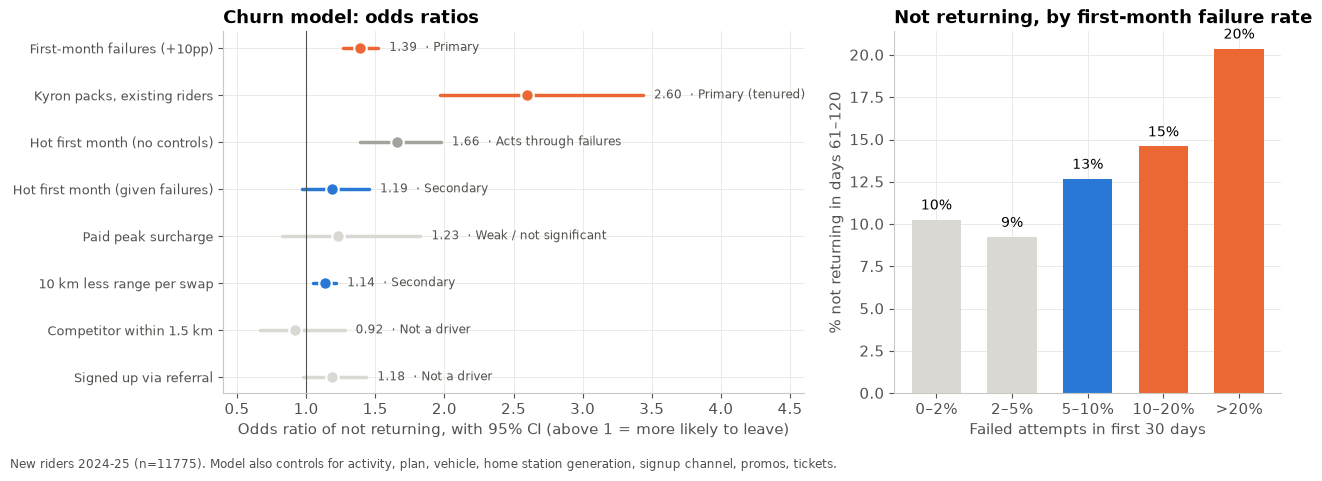

In [34]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios":[1.5,1]})
ax = axs[0]; dd = drivers.iloc[::-1].reset_index(drop=True)
rc = {"Primary": ORANGE, "Primary (tenured)": ORANGE, "Acts through failures": GRAY, "Secondary": BLUE, "Not a driver": LGRAY, "Weak / not significant": LGRAY}
for i, r_ in dd.iterrows():
    ax.plot([r_.lo, r_.hi], [i,i], color=rc[r_.role], lw=2.5, solid_capstyle="round"); ax.plot(r_.OR, i, "o", color=rc[r_.role], ms=9, mec="white", mew=1.5)
    ax.text(max(r_.hi, r_.OR)+0.08, i, f"{r_.OR:.2f}  · {r_.role}", va="center", fontsize=8.5, color=INK2)
ax.axvline(1, color=INK2, lw=.8); ax.set_yticks(range(len(dd)), dd.factor, fontsize=9); ax.set_xlim(0.4, 4.6)
ax.set_xlabel("Odds ratio of not returning, with 95% CI (above 1 = more likely to leave)")
ax.set_title("Churn model: odds ratios")
ax = axs[1]
ax.bar(range(len(fb)), fb["mean"], color=[LGRAY, LGRAY, BLUE, ORANGE, ORANGE], width=.65)
for i, v in enumerate(fb["mean"]): ax.text(i, v+.6, f"{v:.0f}%", ha="center", fontsize=10)
ax.set_xticks(range(len(fb)), fb.index); ax.set_xlabel("Failed attempts in first 30 days"); ax.set_ylabel("% not returning in days 61–120")
ax.set_title("Not returning, by first-month failure rate"); fig.tight_layout()
save(fig, "q6_churn_drivers", "New riders 2024-25 (n=%d). Model also controls for activity, plan, vehicle, home station generation, signup channel, promos, tickets." % len(nr))

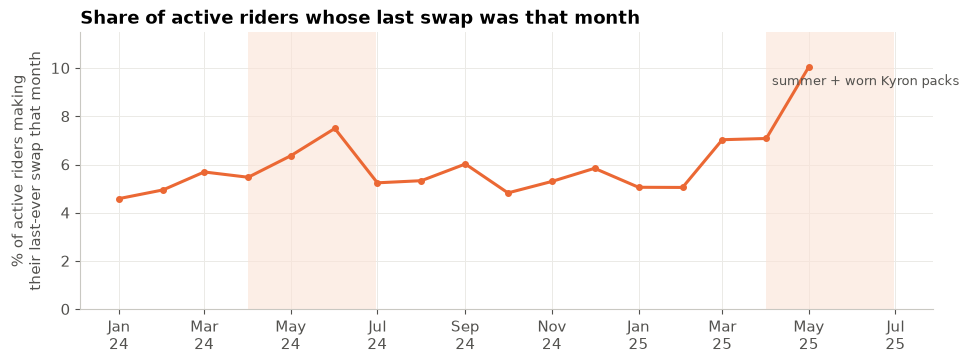

In [35]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(hz.month, hz.churn_pct, color=ORANGE, marker="o", ms=4)
for d in ["2024-04-01","2025-04-01"]: ax.axvspan(pd.Timestamp(d), pd.Timestamp(d)+pd.Timedelta(days=90), color="#fbe3d6", alpha=.6, lw=0)
ax.text(pd.Timestamp("2025-04-05"), 9.3, "summer + worn Kyron packs", fontsize=9, color=INK2)
ax.set_ylabel("% of active riders making\ntheir last-ever swap that month"); ax.set_ylim(0, 11.5)
ax.set_title("Share of active riders whose last swap was that month"); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b\n%y"))
save(fig, "q6_monthly_churn_hazard")

Summary of Q6:

- **Primary:** a bad first month. Riders with >20% failed attempts leave about twice as often as those with almost none.
  For existing riders, being given mostly Kyron packs goes with ~2.6x the odds of leaving.
- **Secondary:** heat. On its own a hot first month looks bad (OR 1.66), but once I control for failures it drops to ~1.19,
  so heat mostly hurts *through* failures. Lower range also matters a little.
- **Not supported:** peak surcharge (OR 1.23 but p about 0.31), competitors opening nearby, competitor promos, signup channel.

This is observational data, so it's association, not proof. But the timing is right (experience before outcome) and the
telemetry gives a plausible mechanism.

## 9. Deep dives
### 9a. What the ticket comments actually say
The `category` field looked off, so I tagged tickets with simple keyword rules on the comment text (English + Hinglish).

In [36]:
tt = Q("select category, text_theme, count(*) n from tickets group by all order by 1, 3 desc")
tq = Q("select date_trunc('quarter', created_ts) q, text_theme, count(*) n from tickets where created_ts>='2024-01-01' and created_ts<'2025-07-01' group by all order by all")
rk = Q("""select case when bt.kyron_bad then 'Kyron bad lots' else bt.supplier end s, avg((t.text_theme='Range / battery')::int)*100 range_share, count(*) n
          from tickets t join batteries bt using(battery_id) group by 1""")
KEY.update(other_tickets=int(tt[tt.category=="other"].n.sum()), range_tickets_q1_24=int(tq[(tq.text_theme=="Range / battery")].n.iloc[0]),
           range_tickets_q2_25=int(tq[(tq.text_theme=="Range / battery")].n.iloc[-1]),
           range_true_total=int(tt[tt.text_theme=="Range / battery"].n.sum()), range_labelled=int(tt[tt.category=="low_range"].n.sum()),
           kyron_range_share=round(rk.set_index("s").range_share["Kyron bad lots"],0), cellora_range_share=round(rk.set_index("s").range_share["Cellora"],0))
display(tt); display(rk.round(1))

,category,text_theme,n
0,app_issue,App,5787
1,billing_dispute,Billing – amount,3156
2,billing_dispute,Billing – surcharge,1559
3,long_queue,Queue,5731
4,low_range,Range / battery,6636
5,no_battery_available,No battery,11647
6,other,Range / battery,9484


,s,range_share,n
0,Cellora,33.3,16163
1,Kyron bad lots,46.7,8073
2,Kyron,4.0,570
3,Amptek,34.3,5959


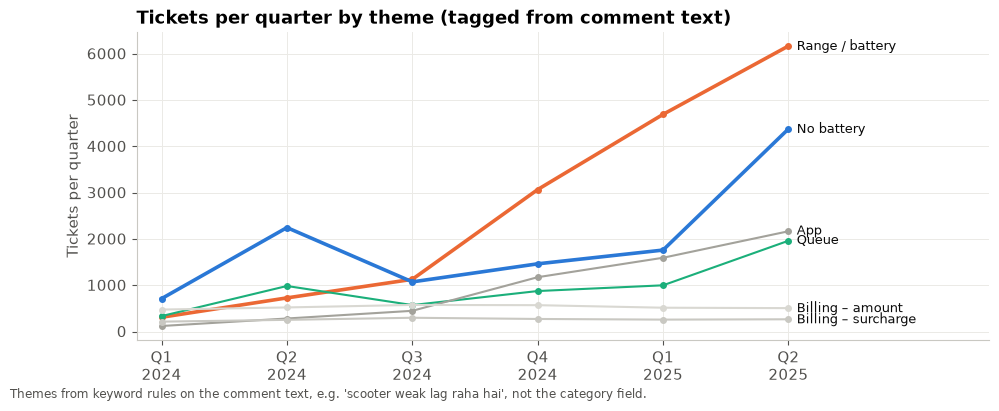

In [37]:
piv = tq.pivot(index="q", columns="text_theme", values="n").fillna(0); piv.index = [f"Q{(d.month-1)//3+1}\n{d.year}" for d in piv.index]
fig, ax = plt.subplots(figsize=(11, 4))
order_t = ["Range / battery","No battery","Queue","App","Billing – amount","Billing – surcharge"]
ctc = {"Range / battery": ORANGE, "No battery": BLUE, "Queue": AQUA, "App": GRAY, "Billing – amount": LGRAY, "Billing – surcharge": "#c9c8c2"}
for t in order_t:
    ax.plot(piv.index, piv[t], color=ctc[t], marker="o", ms=4, lw=2.6 if t in ("Range / battery","No battery") else 1.5)
    ax.annotate(t, (piv.index[-1], piv[t].iloc[-1]), xytext=(6,0), textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_xlim(-0.2, len(piv)+0.6); ax.set_ylabel("Tickets per quarter")
ax.set_title("Tickets per quarter by theme (tagged from comment text)")
save(fig, "q9_ticket_text", "Themes from keyword rules on the comment text, e.g. 'scooter weak lag raha hai', not the category field.")

All 9,484 "other" tickets are range complaints written as vehicle problems ("bike problem", "scooter weak").
Counting those, range is the biggest complaint type and it grew ~20x from Q1 2024 to Q2 2025.

### 9b. Anomalies I came across
- Firmware v3.2.0 clock bug at 61 stations (fixed in cleaning).
- Kyron lots: all 1,385 2W packs retired on one day (15 Jun 2025), but some still appear in swaps afterwards.
- Packs appearing in swaps before their commission date, so the asset records and swap log don't match.
- Test stations have ~₹3.9M of realistic-looking revenue. Easy to accidentally include.
- Fully missing telemetry only happens at 'poor' connectivity stations.
- payment_mode is always `partner_invoice`.

In [38]:
Q("select connectivity_tier, telemetry_status, count(*) n from hourly group by all order by all")

,connectivity_tier,telemetry_status,n
0,fair,ok,267660
1,fair,partial,11004
2,good,ok,938666
3,good,partial,9550
4,poor,missing,9384
5,poor,ok,208999
6,poor,partial,16193


### 9c. The budget question
Leadership is weighing four options. My take on each, based on the above:

- **More stations:** not as proposed. Wave 1 sites are the least used and the hot-city Gen1 problem didn't improve.
  New stations only make sense if they're Gen3 and placed at the problem spots.
- **More batteries:** partly. Stock-outs come from slow charging in heat, not too few packs. But the 1,385 retired
  Kyron packs need replacing anyway.
- **Peak pricing everywhere:** fine as a revenue lever, but it won't fix failures (only ~2.5pp shift).
  Should apply to partners too.
- **Long-term ZipDrop exclusive:** not on current terms, they're negative margin per swap.

What I'd fund instead: fix or cool the Gen1 stations in Delhi/Jaipur/Hyderabad, replace the Kyron packs and check
battery lots properly, renegotiate ZipDrop, and look after new riders in their first month.

Rough size of the failure problem: how many failed attempts were never followed by a successful swap within 2 hours?

In [39]:
# failed attempts with no completed swap by the same rider in the next 2 hours
lost = Q("""with f as (select rider_id, event_ts, charger_generation, city from swaps where service_failure),
  c as (select rider_id, event_ts from swaps where completed)
  select f.charger_generation gen, f.city in ('Delhi NCR','Jaipur','Hyderabad') hot3, count(*) failures,
    sum((not exists (select 1 from c where c.rider_id=f.rider_id and c.event_ts > f.event_ts and c.event_ts <= f.event_ts + interval 2 hour))::int) unrecovered
  from f group by all""")
arps_all = Q("select avg(amount_charged_inr) from swaps where completed").iloc[0,0]
lost["lost_rev_m"] = lost.unrecovered*arps_all/1e6
g1hot = lost[(lost.gen=="Gen1")&(lost.hot3)]
KEY.update(unrecovered_share=round(lost.unrecovered.sum()/lost.failures.sum()*100,1), lost_rev_total_m=round(lost.lost_rev_m.sum(),1),
           lost_rev_gen1hot_m=round(g1hot.lost_rev_m.sum(),1), gen1_hot_stations=int(Q("select count(*) from stations where charger_generation='Gen1' and city in ('Delhi NCR','Jaipur','Hyderabad') and not is_test").iloc[0,0]),
           failures_total=int(lost.failures.sum()))
lost.round(1)

,gen,hot3,failures,unrecovered,lost_rev_m
0,Gen3,False,5983,5565.0,0.4
1,Gen1,True,101148,92781.0,5.9
2,Gen3,True,10399,9413.0,0.6
3,Gen2,True,22460,20503.0,1.3
4,Gen1,False,22738,21192.0,1.4
5,Gen2,False,49121,45890.0,2.9


## 10. Saving the numbers
Dumping the headline numbers to a json so the report and slides use the same values.

In [40]:
KEY = {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k, v in KEY.items()}
json.dump(KEY, open(OUT+"key_numbers.json","w"), indent=1, default=str)
for k, v in KEY.items(): print(f"{k:28s} {v}")

attempts_total               3814982
completed_total              3586675
revenue_total_m              229.2
completed_growth_pct         142.9
revenue_growth_pct           162.7
failures_growth_pct          106.7
fail_rate_h1_24              7.04
fail_rate_h1_25              6.06
cm_jan24                     10.03
cm_jul24                     16.48
cm_nov24                     5.64
cm_jun25                     8.97
cm_h1_24                     10.53
cm_h1_25                     7.57
km_jan24                     73.7
km_jun25                     51.4
peak_fail_month              May 2024
peak_fail_pct                11.9
gen1_fail_40                 19.0
gen3_fail_40                 5.5
fail_cool                    3.9
fail_2w                      5.0
fail_3w                      10.0
top20_share                  31.0
top20_all_gen1               True
top20_cities                 Delhi NCR, Hyderabad, Jaipur
n_stations                   150
gen1_share_failures          58.5
gen1_share_

Tables for the dashboard (`VoltRelay_Dashboard.html`)

In [41]:
Q("""select s.station_id, st.city, st.zone, st.latitude, st.longitude, st.charger_generation gen, st.expansion_wave wave, st.location_type,
     count(*) attempts, avg(service_failure::int)*100 fail_pct, avg(service_failure::int) filter (where month(event_ts) in (4,5,6))*100 summer_fail_pct
     from swaps s join stations st using(station_id) group by all""").to_csv(TAB+"station_summary.csv", index=False)
Q("""select month, city, count(*) attempts, sum(completed::int) completed, avg(service_failure::int)*100 fail_pct, sum(amount_charged_inr)/1e6 revenue_m
     from swaps group by all order by all""").to_csv(TAB+"city_monthly.csv", index=False)
Q("""select month, city, avg(amount_charged_inr-energy_cost-wear_cost) cm_per_swap, avg(km_since_last_swap) km from cm group by all order by all""").to_csv(TAB+"city_monthly_cm.csv", index=False)
heat.to_csv(TAB+"heat_gen.csv", index=False); tel.to_csv(TAB+"telemetry_gen_temp.csv", index=False)
did_m.to_csv(TAB+"peak_pilot_monthly.csv", index=False); tq.to_csv(TAB+"ticket_themes_quarterly.csv", index=False)
soh.to_csv(TAB+"soh_cohort_monthly.csv", index=False); hz.to_csv(TAB+"monthly_churn_hazard.csv", index=False)
print(sorted(os.listdir(TAB)))

['churn_drivers.csv', 'city_failures.csv', 'city_monthly.csv', 'city_monthly_cm.csv', 'cm_bridge.csv', 'heat_gen.csv', 'monthly_churn_hazard.csv', 'monthly_kpis.csv', 'new_rider_churn_model.csv', 'partner_economics_2025H1.csv', 'peak_pilot_monthly.csv', 'soh_cohort_monthly.csv', 'station_summary.csv', 'telemetry_gen_temp.csv', 'ticket_themes_quarterly.csv']


Optional: zip all charts and tables (on Colab, download `voltrelay_outputs.zip` from the Files panel on the left).

In [42]:
if IN_COLAB:
    import shutil
    shutil.make_archive("voltrelay_outputs", "zip", OUT); print("saved voltrelay_outputs.zip")